# ENG 2440 — Assignment 2: Tumor Segmentation in MRI Volumes
**Student:** Brandon-Jason Adebayo · **ID:** 25011100 · **Repository:** https://github.com/B4ryterx/ENG2440-Assignment2

Whole-tumor segmentation of MSD **Task01_BrainTumour** (484 labelled cases, 4 MRI channels) with a lightweight 3D U-Net trained from patches in PyTorch. Supporting code lives in `seg_utils.py`.

> **Clinical scope.** The target is a research reference segmentation, not pathology-confirmed tumor extent. Scores here do not establish safety, clinical usefulness or suitability for treatment planning.

**Run order:** set `DATA_ROOT` in the first code cell, then *Run All* top to bottom. Seeds, hardware and runtime are printed in Section 0 and at the end.

## 0. Configuration and environment

In [ ]:

from pathlib import Path
DATA_ROOT  = Path("Task01_BrainTumour")
SPLIT_FILE = Path("assignment2_split.csv")
OUT_DIR    = Path("outputs");        OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR  = OUT_DIR / "cache";      CACHE_DIR.mkdir(exist_ok=True)  


SEED        = 42
PATCH       = 64        # cubic training / inference patch (voxels = mm here)
BATCH       = 4
ITERS       = 2000      # optimizer steps per training run  (= 8000 patches)
LR          = 1e-3
P_FG        = 0.5       # tumor-aware sampler: probability a patch is centred on tumor
EVAL_EVERY  = 200       # validation monitoring interval (steps)
N_VAL_MONITOR = 8       # validation cases used for Dice monitoring during training
OVERLAP     = 0.5       # sliding-window overlap at inference
THRESH      = 0.5       # probability threshold (applied AFTER blending)
MIN_CC_ML   = 0.5       # postprocessing: remove components smaller than this (mL)
NUM_WORKERS = 4
RETRAIN     = False     # False: reuse checkpoints in outputs/ if they exist
RUN_BONUS   = True

In [2]:
import os, sys, time, json, copy, random, platform, subprocess
from multiprocessing import Pool
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
import torch
from scipy import ndimage

import seg_utils as su

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
try:
    cpu = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
except Exception:
    cpu = platform.processor()
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| nibabel", nib.__version__, "| numpy", np.__version__)
print("Platform:", platform.platform(), "| CPU:", cpu, "| device:", DEVICE)
pd.set_option("display.precision", 3)
NOTEBOOK_T0 = time.time()

Python 3.11.16 | torch 2.13.0 | nibabel 5.4.2 | numpy 2.4.6
Platform: macOS-26.7.1-arm64-arm-64bit | CPU: Apple M4 Max | device: mps


### Setup verification (from the brief)

In [3]:
split_df = pd.read_csv(SPLIT_FILE)
assert len(split_df) == 484
assert set(split_df["split"]) == {"train", "validation", "test"}
for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists()
    assert (DATA_ROOT / row.label_relpath).exists()
print(split_df["split"].value_counts())

split
train         338
test           73
validation     73
Name: count, dtype: int64


---
## A. Define the task and inspect the volumes (10 marks)

### A1 [2] — Input, output, unit of analysis, intended use; voxel / slice / volume / patient case

- **Input:** one co-registered multimodal MRI volume per patient: a 4-channel 3D tensor `[C=4, D, H, W]` (FLAIR, T1, T1ce, T2) at 1 mm isotropic spacing.
- **Output:** a binary 3D mask of the same spatial size, where y(v)=1 for whole tumor (any non-zero reference label: edema, non-enhancing or enhancing tumor) and 0 for background. The network actually outputs a per-voxel tumor probability, which is thresholded at 0.5.
- **Unit of analysis:** the model makes a decision for every **voxel**, but evaluation, data splitting and all reported statistics are per **patient case**, since voxels from the same patient are strongly correlated.
- **Intended technical use:** research and education. It is a reference-style automatic segmentation to study volumetric learning, not a clinical tool and not suitable for treatment planning.
- **Voxel:** the smallest 3D element (here 1×1×1 mm) holding one intensity per channel.
- **Slice:** a 2D cross-section of the volume (axial, coronal or sagittal).
- **Volume:** the complete 3D scan of one acquisition (here 240×240×155 voxels).
- **Patient case:** everything belonging to one patient: the 4 MRI volumes plus the reference label volume (`BRATS_xxx`).

### A2 [3] — Load ≥3 cases: shape, channel order, affine, orientation, spacing, label values

In [4]:
ds_json = json.loads((DATA_ROOT / "dataset.json").read_text())
print("Channel order (dataset.json):", ds_json["modality"])
print("Label values  (dataset.json):", ds_json["labels"], "\n")

inspect_rows = split_df[split_df["split"] == "train"].head(3)
for row in inspect_rows.itertuples():
    img = nib.load(DATA_ROOT / row.image_relpath)
    lbl = nib.load(DATA_ROOT / row.label_relpath)
    print(f"=== {row.case_id} ===")
    print(f"image shape {img.shape}  (X, Y, Z, channel) | label shape {lbl.shape} | dtype {img.get_data_dtype()}")
    print(f"voxel spacing (mm): {tuple(float(v) for v in img.header.get_zooms()[:3])}   (4th zoom {float(img.header.get_zooms()[3])} = channel axis, not mm)")
    print("orientation codes:", nib.aff2axcodes(img.affine), "| label orientation:", nib.aff2axcodes(lbl.affine))
    print("affine:\n", img.affine)
    print("label values present:", np.unique(np.asarray(lbl.dataobj)).astype(int), "\n")

Channel order (dataset.json): {'0': 'FLAIR', '1': 'T1w', '2': 't1gd', '3': 'T2w'}
Label values  (dataset.json): {'0': 'background', '1': 'edema', '2': 'non-enhancing tumor', '3': 'enhancing tumour'} 

=== BRATS_001 ===
image shape (240, 240, 155, 4)  (X, Y, Z, channel) | label shape (240, 240, 155) | dtype float32
voxel spacing (mm): (1.0, 1.0, 1.0)   (4th zoom 1.0 = channel axis, not mm)
orientation codes: ('R', 'A', 'S') | label orientation: ('R', 'A', 'S')
affine:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
label values present: [0 1 2 3] 

=== BRATS_003 ===
image shape (240, 240, 155, 4)  (X, Y, Z, channel) | label shape (240, 240, 155) | dtype float32
voxel spacing (mm): (1.0, 1.0, 1.0)   (4th zoom 1.0 = channel axis, not mm)
orientation codes: ('R', 'A', 'S') | label orientation: ('R', 'A', 'S')
affine:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
label values present: [0 1 2 3] 

=== BRATS_004 ===
image shape (240, 240, 155, 4)  (X, Y, Z, chann

### A3 [2] — One case: FLAIR, T1, T1ce, T2 and reference at the same physical location

Voxel index (i,j,k) = (157, 116, 67)  ->  world RAS coordinate = [157. 116.  67.] mm


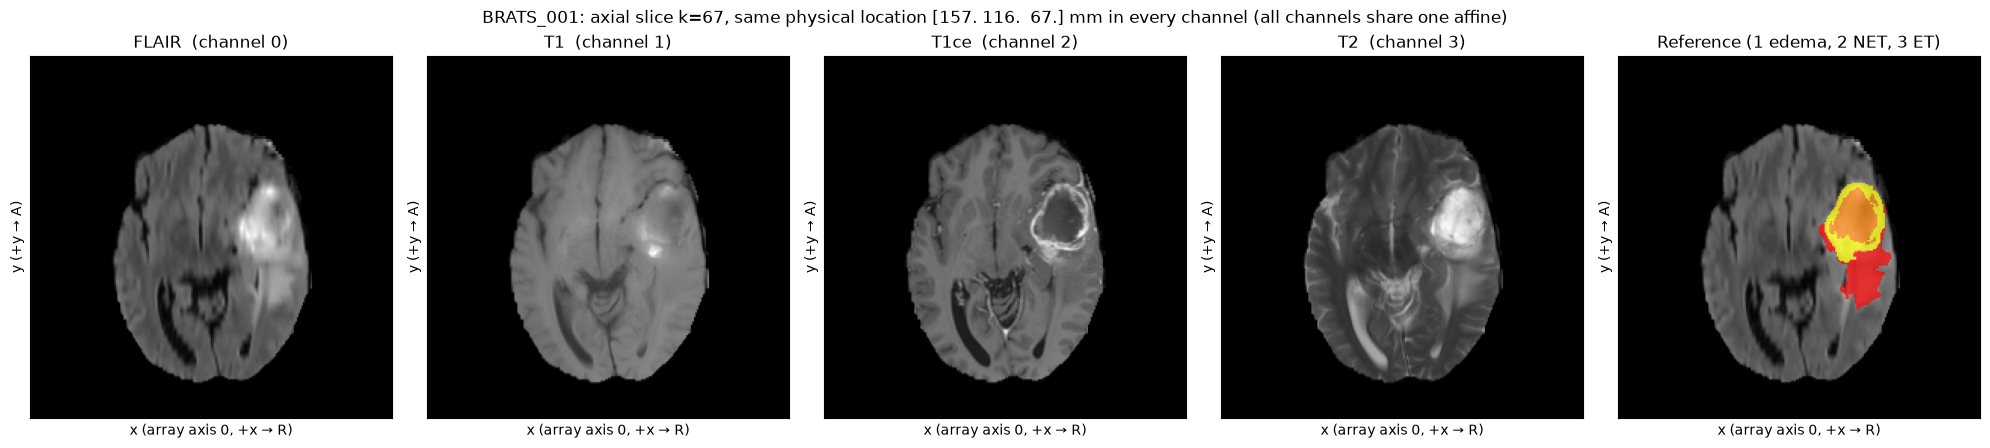

In [5]:
CASE_A = "BRATS_001"
row_a = split_df.set_index("case_id").loc[CASE_A]
img_a = nib.load(DATA_ROOT / row_a.image_relpath)
vol_a = np.asarray(img_a.dataobj, dtype=np.float32)                 # (X, Y, Z, 4)
lab_a = np.asarray(nib.load(DATA_ROOT / row_a.label_relpath).dataobj).astype(np.uint8)

# choose the location by the tumor centroid, then report it in world (scanner) millimetres
centre = tuple(int(round(c)) for c in ndimage.center_of_mass(lab_a > 0))
world = nib.affines.apply_affine(img_a.affine, centre)
print(f"Voxel index (i,j,k) = {centre}  ->  world RAS coordinate = {np.round(world, 1)} mm")

z = centre[2]
fig, axes = plt.subplots(1, 5, figsize=(20, 4.4))
for c, name in enumerate(su.CHANNELS):
    axes[c].imshow(vol_a[:, :, z, c].T, cmap="gray", origin="lower")
    axes[c].set_title(f"{name}  (channel {c})")
axes[4].imshow(vol_a[:, :, z, 0].T, cmap="gray", origin="lower")
m = np.ma.masked_where(lab_a[:, :, z].T == 0, lab_a[:, :, z].T)
im = axes[4].imshow(m, cmap="autumn", origin="lower", alpha=0.7, vmin=1, vmax=3)
axes[4].set_title("Reference (1 edema, 2 NET, 3 ET)")
for ax in axes:
    ax.set_xlabel("x (array axis 0, +x → R)"); ax.set_ylabel("y (+y → A)"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"{CASE_A}: axial slice k={z}, same physical location {np.round(world,1)} mm in every channel "
             "(all channels share one affine)")
plt.tight_layout(); plt.savefig(OUT_DIR / "A3_modalities.png", dpi=110); plt.show()

### A4 [3] — Reference in axial, coronal and sagittal planes; why index order is not enough

Orientation codes: ('R', 'A', 'S') -> array axis 0 increases towards R , axis 1 towards A , axis 2 towards S


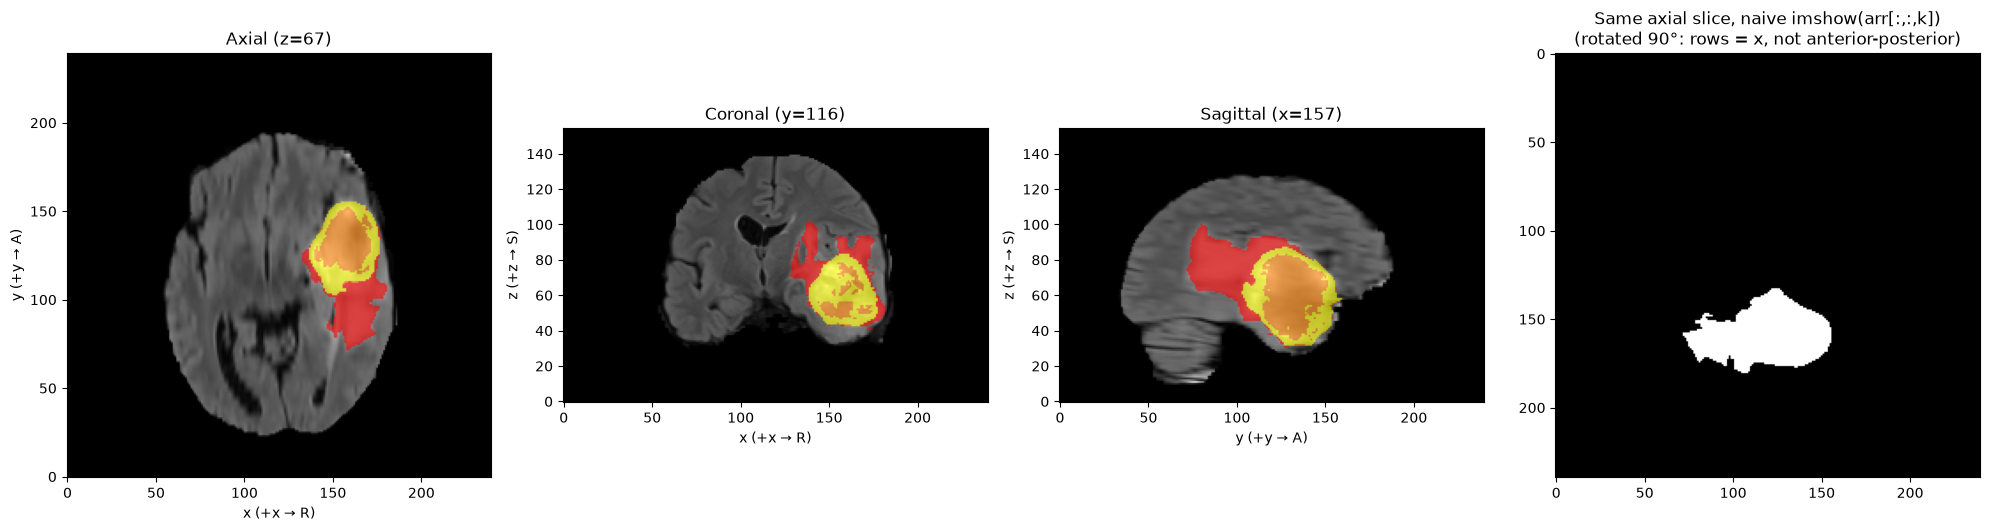

In [6]:
codes = nib.aff2axcodes(img_a.affine)
print("Orientation codes:", codes, "-> array axis 0 increases towards", codes[0], ", axis 1 towards", codes[1], ", axis 2 towards", codes[2])

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
flair = vol_a[..., 0]
for ax, (title, sl), (lab_title, lsl) in zip(axes[:3], su.plane_slices(flair, centre).items(),
                                              su.plane_slices(lab_a, centre).items()):
    ax.imshow(sl, cmap="gray", origin="lower")
    ax.imshow(np.ma.masked_where(lsl == 0, lsl), cmap="autumn", origin="lower", alpha=0.6, vmin=1, vmax=3)
    ax.set_title(title)
axes[0].set_xlabel("x (+x → R)"); axes[0].set_ylabel("y (+y → A)")
axes[1].set_xlabel("x (+x → R)"); axes[1].set_ylabel("z (+z → S)")
axes[2].set_xlabel("y (+y → A)"); axes[2].set_ylabel("z (+z → S)")
# naive display: plotting the raw array index order
axes[3].imshow(lab_a[:, :, z] > 0, cmap="gray")
axes[3].set_title("Same axial slice, naive imshow(arr[:,:,k])\n(rotated 90°: rows = x, not anterior-posterior)")
plt.tight_layout(); plt.savefig(OUT_DIR / "A4_three_planes.png", dpi=110); plt.show()

**Why file-index order is not enough.** A NIfTI array is just numbers stored in index order (i, j, k). What those indices mean physically is defined by the **affine**: which anatomical direction each axis points to (here the codes are R, A, S: index i increases towards the patient's Right, j towards Anterior, k towards Superior), the spacing in mm, and where the origin is. Without it:
1. **Left/right can silently flip.** Another scanner or dataset may store LPS or LAS. The same index then refers to the opposite hemisphere, which is a dangerous error for laterality.
2. **Distances and volumes are wrong** if spacing is anisotropic (e.g. 0.9×0.9×5 mm). A voxel count or a distance in voxels is not a physical quantity.
3. **Plotting depends on index order.** The rightmost panel shows the same axial slice drawn with the raw index order: `imshow` puts array axis 0 on the rows, so the brain appears rotated by 90°. "Axial / coronal / sagittal" are only defined after mapping indices through the affine.
4. **Multimodal data and labels are only aligned** if they share the same affine. Matching array shapes alone do not prove co-registration.

Here all cases are RAS with an identity affine and 1 mm spacing, so index (i,j,k) equals world (x,y,z) mm. This is a property we *verified* (Section C1), not one we assumed.

---
## B. Reproducible case-level split (8 marks)

### B1 [2] — Use the supplied split exactly (case level)

In [7]:
split_df = pd.read_csv(SPLIT_FILE)                      # used as-is, never re-shuffled
assert split_df["case_id"].is_unique, "a case appears twice -> split would not be case-level"
assert len(split_df) == 484
train_ids = sorted(split_df.loc[split_df.split == "train", "case_id"])
val_ids   = sorted(split_df.loc[split_df.split == "validation", "case_id"])
test_ids  = sorted(split_df.loc[split_df.split == "test", "case_id"])
print("Each case_id occurs once and belongs to exactly one split -> patches/slices of a patient can never cross splits.")
print({"train": len(train_ids), "validation": len(val_ids), "test": len(test_ids)})

Each case_id occurs once and belongs to exactly one split -> patches/slices of a patient can never cross splits.
{'train': 338, 'validation': 73, 'test': 73}


### B2 [3] — Files exist and case IDs are disjoint

In [8]:
missing = [p for r in split_df.itertuples() for p in (DATA_ROOT / r.image_relpath, DATA_ROOT / r.label_relpath) if not p.exists()]
print("Missing files:", len(missing))
assert not missing
tr, va, te = set(train_ids), set(val_ids), set(test_ids)
overlaps = {"train∩val": len(tr & va), "train∩test": len(tr & te), "val∩test": len(va & te)}
print("Overlaps:", overlaps)
assert sum(overlaps.values()) == 0
# image and label file names must refer to the same case
assert all(Path(r.image_relpath).name == Path(r.label_relpath).name == f"{r.case_id}.nii.gz" for r in split_df.itertuples())
print("Disjoint check passed; image/label filenames match their case_id.")

Missing files: 0
Overlaps: {'train∩val': 0, 'train∩test': 0, 'val∩test': 0}
Disjoint check passed; image/label filenames match their case_id.


### B3 [3] — Case counts and reference tumor-volume distribution (test labels stay unused)

Whole-tumor reference volume (mL) per split; test volumes are reported only in Section F:


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,338.0,102.964,56.96,8.478,60.023,95.484,143.921,265.254
validation,73.0,100.765,62.95,7.285,51.853,91.560,148.062,266.936
test,73.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


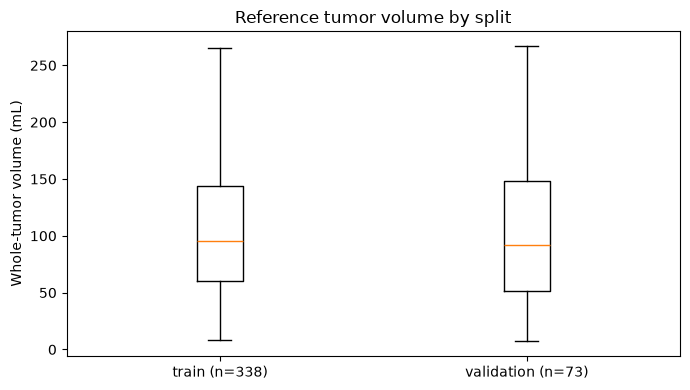

In [9]:
def tumor_ml_from_label(relpath):
    l = nib.load(DATA_ROOT / relpath)
    return float((np.asarray(l.dataobj) > 0).sum() * np.prod(l.header.get_zooms()[:3]) / 1000.0)

vol_rows = []
for r in split_df[split_df.split != "test"].itertuples():        # test labels deliberately NOT read here
    vol_rows.append(dict(case_id=r.case_id, split=r.split, tumor_ml=tumor_ml_from_label(r.label_relpath)))
vol_df = pd.DataFrame(vol_rows)
summary_b3 = vol_df.groupby("split")["tumor_ml"].describe()[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
summary_b3.loc["test"] = [len(test_ids)] + [np.nan] * 7
print("Whole-tumor reference volume (mL) per split; test volumes are reported only in Section F:")
display(summary_b3)

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([vol_df.loc[vol_df.split == s, "tumor_ml"] for s in ["train", "validation"]],
           tick_labels=[f"train (n={len(train_ids)})", f"validation (n={len(val_ids)})"])
ax.set_ylabel("Whole-tumor volume (mL)"); ax.set_title("Reference tumor volume by split")
plt.tight_layout(); plt.savefig(OUT_DIR / "B3_volume_by_split.png", dpi=110); plt.show()

**B3 interpretation.** The split is case-level and balanced in tumor burden. Training: 338 cases, mean 103.0 mL (SD 57.0, median 95.5, range 8.5–265.3 mL). Validation: 73 cases, mean 100.8 mL (SD 63.0, median 91.6, range 7.3–266.9 mL). Volumes vary about 30-fold between patients, so a per-case average Dice gives small tumors the same weight as huge ones. Test labels were **not** opened here: the 73 test volumes (mean 107.4 mL, median 89.1, range 10.1–318.3 mL) are reported in F2, after the model and every setting were frozen. The test maximum (318 mL) exceeds anything seen in training, which is a small distribution-shift risk.

---
## C. Preprocess MRI and labels safely (12 marks)

### C1 [3] — Verify geometry across all four channels and the label (all 484 cases)

In [ ]:

geo = []
for r in split_df.itertuples():
    im = nib.load(DATA_ROOT / r.image_relpath); lb = nib.load(DATA_ROOT / r.label_relpath)
    geo.append(dict(case_id=r.case_id, split=r.split,
                    img_shape=im.shape, lbl_shape=lb.shape, n_channels=im.shape[3],
                    spacing=tuple(float(v) for v in im.header.get_zooms()[:3]),
                    lbl_spacing=tuple(float(v) for v in lb.header.get_zooms()[:3]),
                    orient="".join(nib.aff2axcodes(im.affine)),
                    same_grid=(im.shape[:3] == lb.shape) and np.allclose(im.affine, lb.affine)))
geo_df = pd.DataFrame(geo)
print("unique image shapes   :", geo_df.img_shape.unique())
print("unique label shapes   :", geo_df.lbl_shape.unique())
print("channels per image    :", geo_df.n_channels.unique())
print("unique spacings (mm)  :", geo_df.spacing.unique(), "| label:", geo_df.lbl_spacing.unique())
print("unique orientations   :", list(geo_df.orient.unique()))
print("cases where image and label grids differ:", int((~geo_df.same_grid).sum()))
assert geo_df.same_grid.all() and (geo_df.n_channels == 4).all()

unique image shapes   : [(240, 240, 155, 4)]
unique label shapes   : [(240, 240, 155)]
channels per image    : [4]
unique spacings (mm)  : [(1.0, 1.0, 1.0)] | label: [(1.0, 1.0, 1.0)]
unique orientations   : ['RAS']
cases where image and label grids differ: 0


All 484 cases share one grid: 240×240×155 voxels, 1.0 mm isotropic, RAS orientation, and an affine identical between image and label. The four channels live in one 4D NIfTI with a single affine, so they are co-registered by construction. **No resampling is needed.** The target grid is the native grid (240×240×155 at 1 mm, RAS), and every prediction is evaluated on it. Resampling anyway would only add interpolation blur and label errors.

### C2 [2] — Linear interpolation for MRI, nearest-neighbour for labels (demonstration)

Original label values          : [0 1 2 3]
Nearest-neighbour label values : [0 1 2 3]  -> still valid classes
Linear-interpolated label values: 301 distinct values, e.g. [0.01 0.02 0.03 0.04 0.05 0.06 0.07] ... -> invalid (fractions, and edema/ET boundaries become fake 'class 2')
Resampled shapes: (160, 160, 103) (160, 160, 103) | tumor mL orig vs NN: 111.7 110.6


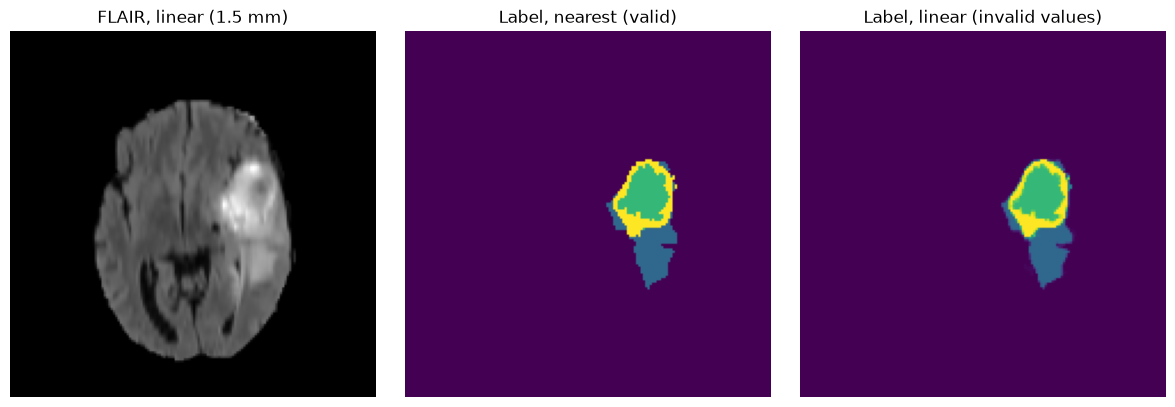

In [ ]:

zoom = 1 / 1.5
flair_rs = ndimage.zoom(vol_a[..., 0], zoom, order=1)          # linear for intensities
lab_nn   = ndimage.zoom(lab_a, zoom, order=0)                  # nearest neighbour for labels
lab_lin  = ndimage.zoom(lab_a.astype(np.float32), zoom, order=1)  # WRONG on purpose
print("Original label values          :", np.unique(lab_a))
print("Nearest-neighbour label values :", np.unique(lab_nn), " -> still valid classes")
bad = np.unique(np.round(lab_lin, 2))
print(f"Linear-interpolated label values: {len(bad)} distinct values, e.g. {bad[1:8]} ... -> invalid "
      "(fractions, and edema/ET boundaries become fake 'class 2')")
print("Resampled shapes:", flair_rs.shape, lab_nn.shape, "| tumor mL orig vs NN:",
      round((lab_a > 0).sum() / 1000, 1), round((lab_nn > 0).sum() * 1.5**3 / 1000, 1))
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
k = int(round(z * zoom))
ax[0].imshow(flair_rs[:, :, k].T, cmap="gray", origin="lower"); ax[0].set_title("FLAIR, linear (1.5 mm)")
ax[1].imshow(lab_nn[:, :, k].T, cmap="viridis", origin="lower", vmin=0, vmax=3); ax[1].set_title("Label, nearest (valid)")
ax[2].imshow(lab_lin[:, :, k].T, cmap="viridis", origin="lower", vmin=0, vmax=3); ax[2].set_title("Label, linear (invalid values)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### C3 [3] — Per-channel normalisation on non-zero brain voxels

In [ ]:

args = [(str(DATA_ROOT), str(CACHE_DIR), r.case_id, r.image_relpath, r.label_relpath, r.split, PATCH)
        for r in split_df.itertuples()]
with su.Timer() as t_prep, Pool(min(8, os.cpu_count())) as pool:
    metas = pool.map(su.preprocess_case, args)
META = {m["case_id"]: m for m in metas}
print(f"Preprocessed {len(META)} cases in {t_prep.dt/60:.1f} min -> {CACHE_DIR} (existing cache files are reused)")

Preprocessed 484 cases in 0.0 min -> outputs/cache (existing cache files are reused)


In [ ]:

rows = []
for cid in train_ids[:3]:
    x = np.load(CACHE_DIR / f"{cid}_img.npy").astype(np.float32)
    brain = np.any(x != 0, axis=0)
    for c, name in enumerate(su.CHANNELS):
        mu_raw, sd_raw = META[cid]["norm_stats"][c]
        v = x[c][brain]
        rows.append(dict(case=cid, channel=name, raw_mean=mu_raw, raw_std=sd_raw,
                         norm_mean=v.mean(), norm_std=v.std(), background_value=float(x[c][~brain].max())))
display(pd.DataFrame(rows))

# Aggregate over ALL training cases
agg = {n: [] for n in su.CHANNELS}
for cid in train_ids:
    x = np.load(CACHE_DIR / f"{cid}_img.npy", mmap_mode="r")
    xs = np.asarray(x[:, ::2, ::2, ::2], dtype=np.float32)      # subsample for speed
    brain = np.any(xs != 0, axis=0)
    for c, n in enumerate(su.CHANNELS):
        agg[n].append((xs[c][brain].mean(), xs[c][brain].std()))
print("Across all training cases (brain voxels), mean ± sd of the per-case normalised mean / std:")
for n in su.CHANNELS:
    a = np.array(agg[n]); print(f"  {n:5s}: mean {a[:,0].mean():+.3f} ± {a[:,0].std():.3f} | std {a[:,1].mean():.3f} ± {a[:,1].std():.3f}")

flair_raw = vol_a[..., 0]
print(f"\nWhy non-zero voxels: FLAIR mean of the whole array = {flair_raw.mean():.1f}, "
      f"of brain voxels only = {flair_raw[flair_raw > 0].mean():.1f} "
      f"({100 * (flair_raw == 0).mean():.0f}% of the array is zero background).")

,case,channel,raw_mean,raw_std,norm_mean,norm_std,background_value
0,BRATS_001,FLAIR,513.633,214.294,-3.250e-06,1.0,0.0
1,BRATS_001,T1,777.332,212.254,-3.051e-06,1.0,0.0
2,BRATS_001,T1ce,725.281,243.643,1.359e-06,1.0,0.0
3,BRATS_001,T2,469.839,212.776,1.672e-06,1.0,0.0
4,BRATS_003,FLAIR,490.335,236.433,-1.251e-05,1.0,0.0
5,BRATS_003,T1,757.480,223.892,2.877e-06,1.0,0.0
6,BRATS_003,T1ce,451.412,226.301,-5.612e-06,1.0,0.0
7,BRATS_003,T2,490.970,211.976,3.128e-06,1.0,0.0
8,BRATS_004,FLAIR,573.534,191.932,-5.843e-06,1.0,0.0
9,BRATS_004,T1,793.593,197.750,1.525e-06,1.0,0.0


Across all training cases (brain voxels), mean ± sd of the per-case normalised mean / std:
  FLAIR: mean +0.000 ± 0.002 | std 1.000 ± 0.002
  T1   : mean +0.000 ± 0.002 | std 0.999 ± 0.004
  T1ce : mean -0.001 ± 0.002 | std 0.999 ± 0.004
  T2   : mean +0.001 ± 0.002 | std 1.000 ± 0.002

Why non-zero voxels: FLAIR mean of the whole array = 86.0, of brain voxels only = 516.3 (83% of the array is zero background).


Each channel of each case is z-scored with the mean and SD of **brain voxels only** (brain = non-zero in any channel). The resulting brain mean is 0 and SD is 1 (small deviations come from float16 storage), and the background stays exactly 0. If the zero background (~85% of the array) were included, the mean would be pulled towards 0 and the SD inflated. Brain intensities would then be scaled by an amount that depends on head size and field of view rather than tissue contrast. Statistics are per case, so no information leaks between splits.

### C4 [4] — Consistent crop/pad and training-only augmentation

Crop rule: bounding box of brain voxels (computed from the IMAGE only) + 4-voxel margin;
           same box applied to every channel and to the label; then zero-pad at the end to >= PATCH.
Cropped spatial size  min [130 152 127]  median [146 177 143]  max [168 195 153]
Cases needing padding: 0/484  | background removed: 59% of voxels
The crop box is stored per case so predictions are pasted back into the original 240x240x155 grid.


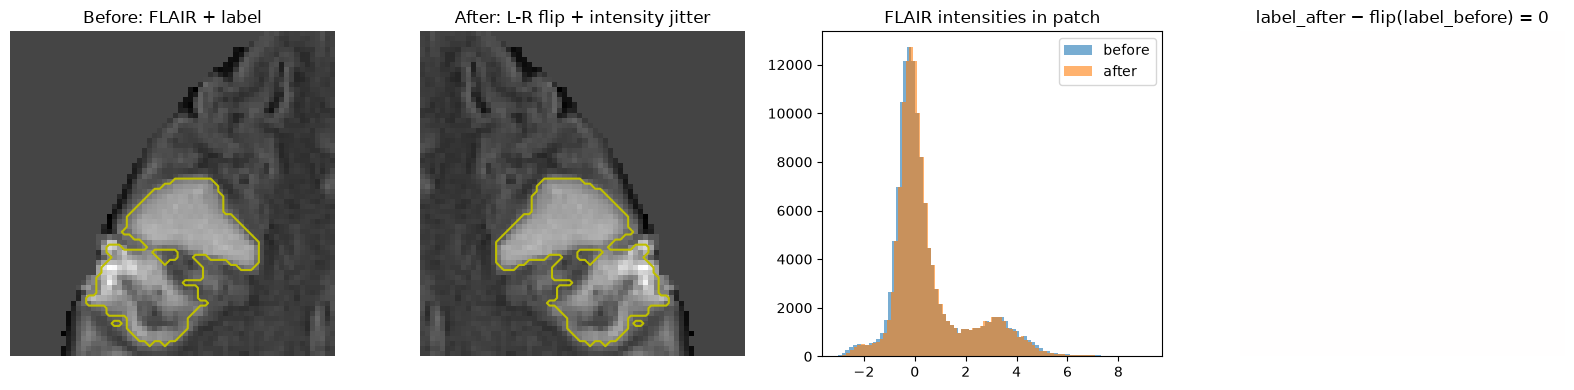

Label values after augmentation: [0. 1.] | validation/test datasets use augment_on=False


In [ ]:
shapes = np.array([m["cached_shape"][1:] for m in metas])
padded = sum(any(p[1] > 0 for p in m["pads"]) for m in metas)
print("Crop rule: bounding box of brain voxels (computed from the IMAGE only) + 4-voxel margin;")
print("           same box applied to every channel and to the label; then zero-pad at the end to >= PATCH.")
print("Cropped spatial size  min", shapes.min(0), " median", np.median(shapes, 0).astype(int), " max", shapes.max(0))
print(f"Cases needing padding: {padded}/{len(metas)}  | background removed: "
      f"{100 * (1 - np.prod(shapes, 1).mean() / (240 * 240 * 155)):.0f}% of voxels")
print("The crop box is stored per case so predictions are pasted back into the original 240x240x155 grid.")


demo_ds  = su.PatchDataset(train_ids, CACHE_DIR, PATCH, 10, "tumor", 1.0, seed=SEED, augment_on=False)
x0, y0, _ = demo_ds[3]
x0, y0 = x0.numpy(), y0.numpy()
aug_seed = next(s for s in range(100) if np.random.default_rng(s).random() < 0.5)   # a draw that flips, for display
x1, y1 = su.augment(x0, y0, np.random.default_rng(aug_seed))
k = PATCH // 2
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(x0[0, :, :, k].T, cmap="gray", origin="lower"); ax[0].contour(y0[0, :, :, k].T, [0.5], colors="y")
ax[0].set_title("Before: FLAIR + label")
ax[1].imshow(x1[0, :, :, k].T, cmap="gray", origin="lower"); ax[1].contour(y1[0, :, :, k].T, [0.5], colors="y")
ax[1].set_title("After: L-R flip + intensity jitter")
ax[2].hist(x0[0][x0[0] != 0].ravel(), 80, alpha=.6, label="before"); ax[2].hist(x1[0][x1[0] != 0].ravel(), 80, alpha=.6, label="after")
ax[2].legend(); ax[2].set_title("FLAIR intensities in patch")
ax[3].imshow((y1[0, :, :, k] - y0[0, ::-1, :, k]).T, cmap="bwr", origin="lower", vmin=-1, vmax=1)
ax[3].set_title("label_after − flip(label_before) = 0")
for a in (ax[0], ax[1], ax[3]): a.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "C4_augmentation.png", dpi=110); plt.show()
print("Label values after augmentation:", np.unique(y1), "| validation/test datasets use augment_on=False")

**Justification.**
- **Crop to the brain box:** removes ~60% of the voxels, all of them zero background, which speeds up sampling and inference and makes "uniform" sampling uniform over the head rather than over empty air. The box comes from the image only, so it can be applied identically to test cases. Padding guarantees that every volume can hold a full patch.
- **Left–right flip (p=0.5):** the brain is roughly symmetric and gliomas occur in both hemispheres. A flip is an exact voxel permutation, so the label stays exactly binary with no interpolation. It is applied identically to all 4 channels and to the mask.
- **Per-channel intensity scale/shift (×0.9–1.1, ±0.1 SD) inside the brain:** mimics scanner and protocol variation without changing anatomy. The label is untouched.
- **Not used:** rotations and elastic deformation, which need interpolation (risking label corruption and costing CPU time), and anterior-posterior or superior-inferior flips, which produce anatomically impossible brains.
- **Training only:** augmentation is applied in the training `PatchDataset` only. Validation and test volumes are never augmented, so evaluation reflects the real data distribution.

---
## D. Patch-based volumetric training (20 marks)

### D1 [3] — Dataset / DataLoader returning `[C,D,H,W]` and `[1,D,H,W]`

In [ ]:
train_uniform_ds = su.PatchDataset(train_ids, CACHE_DIR, PATCH, ITERS * BATCH, "uniform", P_FG, seed=SEED)
train_tumor_ds   = su.PatchDataset(train_ids, CACHE_DIR, PATCH, ITERS * BATCH, "tumor",   P_FG, seed=SEED)

val_patch_ds = su.PatchDataset(val_ids, CACHE_DIR, PATCH, 64, "uniform", seed=SEED + 1000, augment_on=False)
val_patch_loader = torch.utils.data.DataLoader(val_patch_ds, batch_size=BATCH, shuffle=False)
VAL_MONITOR_IDS = val_ids[:N_VAL_MONITOR]

loader = torch.utils.data.DataLoader(train_uniform_ds, batch_size=BATCH, num_workers=0)
xb, yb, fb = next(iter(loader))
print("image batch:", tuple(xb.shape), xb.dtype, "-> [B, C, D, H, W]")
print("mask  batch:", tuple(yb.shape), yb.dtype, "-> [B, 1, D, H, W]")
print("mask values:", torch.unique(yb).tolist(), "| tumor-voxel fraction per patch:", np.round(fb.numpy(), 3))
print("image range: [%.2f, %.2f], channel means %s" % (xb.min(), xb.max(), np.round(xb.mean((0, 2, 3, 4)).numpy(), 3)))
assert xb.shape[1:] == (4, PATCH, PATCH, PATCH) and yb.shape[1:] == (1, PATCH, PATCH, PATCH)
assert set(torch.unique(yb).tolist()) <= {0.0, 1.0}
print("Axis meaning: D = x (R-L), H = y (A-P), W = z (S-I); spacing 1 mm on all three.")

image batch: (4, 4, 64, 64, 64) torch.float32 -> [B, C, D, H, W]
mask  batch: (4, 1, 64, 64, 64) torch.float32 -> [B, 1, D, H, W]
mask values: [0.0, 1.0] | tumor-voxel fraction per patch: [0.004 0.    0.064 0.101]
image range: [-5.51, 11.56], channel means [0.168 0.149 0.069 0.264]
Axis meaning: D = x (R-L), H = y (A-P), W = z (S-I); spacing 1 mm on all three.


### D2 [5] — Lightweight 3D U-Net

In [ ]:
set_seed(SEED)
model = su.UNet3D(in_ch=4, out_ch=1, base=16)
INIT_STATE = copy.deepcopy(model.state_dict())          
torch.save(INIT_STATE, OUT_DIR / "init_weights.pt")
with torch.no_grad():
    out = model(torch.zeros(1, 4, PATCH, PATCH, PATCH))
print(model)
print(f"\nInput channels : 4 (FLAIR, T1, T1ce, T2)")
print(f"Output channels: 1 (whole-tumor logit -> sigmoid probability)")
print(f"Parameters     : {su.count_params(model):,}")
print(f"Patch size     : {PATCH}^3 voxels = {PATCH} mm cube; output shape {tuple(out.shape)}")
print("Encoder widths 16-32-64-128, 3 down-samplings (receptive field covers most of the patch), InstanceNorm + LeakyReLU.")

UNet3D(
  (enc): ModuleList(
    (0): ConvBlock(
      (net): Sequential(
        (0): Conv3d(4, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
        (1): InstanceNorm3d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=False)
        (2): LeakyReLU(negative_slope=0.01, inplace=True)
        (3): Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
        (4): InstanceNorm3d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=False)
        (5): LeakyReLU(negative_slope=0.01, inplace=True)
      )
    )
    (1): ConvBlock(
      (net): Sequential(
        (0): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
        (1): InstanceNorm3d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=False)
        (2): LeakyReLU(negative_slope=0.01, inplace=True)
        (3): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), p

### D3 [4] — Train with **uniform random patches**

In [ ]:
print(f"Loss: BCE-with-logits + soft Dice (equal weights) | Optimizer: Adam, lr={LR}, poly decay (1-t/T)^0.9, grad-clip 5")
print(f"Budget: {ITERS} steps x batch {BATCH} = {ITERS*BATCH} patches of {PATCH}^3 | seed {SEED} | device {DEVICE}")

def run_or_load(name, ds):
    hist_path, ckpt = OUT_DIR / f"{name}_history.json", OUT_DIR / f"{name}_best.pt"
    m = su.UNet3D(4, 1, 16); m.load_state_dict(INIT_STATE)         
    if not RETRAIN and hist_path.exists() and ckpt.exists():
        print(f"Loading existing {name} run (set RETRAIN=True to retrain)")
        return json.loads(hist_path.read_text())
    return su.train_run(name, m, ds, val_patch_loader, VAL_MONITOR_IDS, CACHE_DIR, DEVICE,
                        iters=ITERS, batch_size=BATCH, lr=LR, eval_every=EVAL_EVERY,
                        num_workers=NUM_WORKERS, out_dir=OUT_DIR)

hist_uniform = run_or_load("uniform", train_uniform_ds)
print(f"Uniform: best monitor val Dice {hist_uniform['best_val_dice_subset']:.3f}, {hist_uniform['train_minutes']:.1f} min")

Loss: BCE-with-logits + soft Dice (equal weights) | Optimizer: Adam, lr=0.001, poly decay (1-t/T)^0.9, grad-clip 5
Budget: 2000 steps x batch 4 = 8000 patches of 64^3 | seed 42 | device mps


[uniform] it   200/2000  train 1.1113  val_loss 0.8712  val_dice 0.6397  (3.6 min)


[uniform] it   400/2000  train 0.6669  val_loss 0.5600  val_dice 0.7331  (7.0 min)


[uniform] it   600/2000  train 0.4573  val_loss 0.4579  val_dice 0.7639  (10.3 min)


[uniform] it   800/2000  train 0.3885  val_loss 0.4056  val_dice 0.7866  (13.7 min)


...

[uniform] it  1400/2000  train 0.2917  val_loss 0.3192  val_dice 0.8260  (27.3 min)


[uniform] it  1600/2000  train 0.2605  val_loss 0.3166  val_dice 0.8083  (30.7 min)


[uniform] it  1800/2000  train 0.2633  val_loss 0.3157  val_dice 0.8288  (34.0 min)


[uniform] it  2000/2000  train 0.2478  val_loss 0.3121  val_dice 0.8309  (37.4 min)


Uniform: best monitor val Dice 0.831, 37.4 min


### D4 [5] — Same model with **tumor-aware sampling** (same init, budget, case sequence)

In [18]:
hist_tumor = run_or_load("tumor", train_tumor_ds)
print(f"Tumor-aware: best monitor val Dice {hist_tumor['best_val_dice_subset']:.3f}, {hist_tumor['train_minutes']:.1f} min")

samp = pd.DataFrame({
    "sampler": ["uniform", f"tumor-aware (p_fg={P_FG})"],
    "patches containing tumor": [hist_uniform["tumor_patch_fraction"], hist_tumor["tumor_patch_fraction"]],
    "mean tumor-voxel fraction": [hist_uniform["tumor_voxel_fraction"], hist_tumor["tumor_voxel_fraction"]],
    "patches seen": [ITERS * BATCH] * 2})
display(samp)

[tumor] it   200/2000  train 0.9509  val_loss 0.9824  val_dice 0.6164  (3.4 min)


[tumor] it   400/2000  train 0.5908  val_loss 0.6552  val_dice 0.7348  (6.7 min)


[tumor] it   600/2000  train 0.3895  val_loss 0.6211  val_dice 0.6283  (9.9 min)


[tumor] it   800/2000  train 0.3475  val_loss 0.4644  val_dice 0.7784  (13.2 min)


[tumor] it  1000/2000  train 0.2767  val_loss 0.4433  val_dice 0.7737  (16.5 min)


...

[tumor] it  1600/2000  train 0.2356  val_loss 0.3501  val_dice 0.8532  (26.5 min)


[tumor] it  1800/2000  train 0.2223  val_loss 0.3631  val_dice 0.8460  (29.9 min)


[tumor] it  2000/2000  train 0.2097  val_loss 0.3661  val_dice 0.8364  (33.3 min)


Tumor-aware: best monitor val Dice 0.853, 33.3 min


,sampler,patches containing tumor,mean tumor-voxel fraction,patches seen
0,uniform,0.745,0.068,8000
1,tumor-aware (p_fg=0.5),0.875,0.141,8000


Controls: both runs start from the same saved initial weights (`init_weights.pt`) and use the same optimizer, LR schedule, loss, patch size, batch and number of steps. Every patch index uses an RNG seeded by `(SEED, index)`, so both runs visit **the same sequence of training cases** with the same augmentation draws. Only the patch *location* rule differs.

### D5 [3] — Training / validation loss and validation Dice

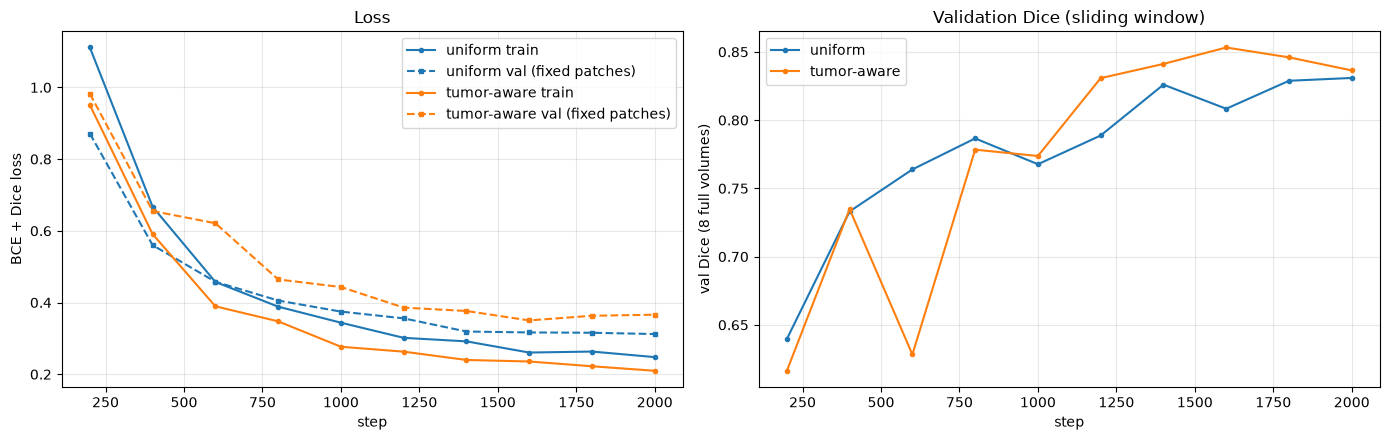

,uni_iter,uni_train_loss,uni_val_loss,uni_val_dice,tum_train_loss,tum_val_loss,tum_val_dice
0,200.0,1.111,0.871,0.640,0.951,0.982,0.616
1,400.0,0.667,0.560,0.733,0.591,0.655,0.735
2,600.0,0.457,0.458,0.764,0.390,0.621,0.628
3,800.0,0.389,0.406,0.787,0.348,0.464,0.778
4,1000.0,0.344,0.375,0.768,0.277,0.443,0.774
5,1200.0,0.302,0.356,0.789,0.263,0.386,0.831
6,1400.0,0.292,0.319,0.826,0.240,0.376,0.841
7,1600.0,0.261,0.317,0.808,0.236,0.350,0.853
8,1800.0,0.263,0.316,0.829,0.222,0.363,0.846
9,2000.0,0.248,0.312,0.831,0.210,0.366,0.836


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for h, name, col in [(hist_uniform, "uniform", "tab:blue"), (hist_tumor, "tumor-aware", "tab:orange")]:
    ax[0].plot(h["iter"], h["train_loss"], "-o", c=col, ms=3, label=f"{name} train")
    ax[0].plot(h["iter"], h["val_loss"], "--s", c=col, ms=3, label=f"{name} val (fixed patches)")
    ax[1].plot(h["iter"], h["val_dice"], "-o", c=col, ms=3, label=name)
ax[0].set_xlabel("step"); ax[0].set_ylabel("BCE + Dice loss"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].set_xlabel("step"); ax[1].set_ylabel(f"val Dice ({N_VAL_MONITOR} full volumes)"); ax[1].legend(); ax[1].set_title("Validation Dice (sliding window)")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "D5_curves.png", dpi=110); plt.show()
display(pd.DataFrame({k: hist_uniform[k] for k in ["iter", "train_loss", "val_loss", "val_dice"]}).add_prefix("uni_")
        .join(pd.DataFrame({k: hist_tumor[k] for k in ["train_loss", "val_loss", "val_dice"]}).add_prefix("tum_")))

**D5 interpretation (validation only).**
- **No clear overfitting, mild underfitting.** For both samplers the training loss falls almost monotonically (uniform 1.11 → 0.25, tumor-aware 0.95 → 0.21). The validation loss falls with it, and the gap stays small. The uniform run's validation Dice is still rising at step 2000 (0.83), so the model is **budget-limited**: more steps would most likely help.
- **Instability:** the tumor-aware run dips at step 600 (monitor Dice 0.735 → 0.628 while training loss keeps falling), then recovers to 0.78 by step 800. This happens early, at a high learning rate, when batches are dominated by tumor; the model briefly over-predicts tumor on whole volumes. The smaller uniform dips (steps 1000 and 1600) are of the order of the noise from monitoring only 8 validation volumes.
- **Late-phase signal:** tumor-aware monitor Dice peaks at step 1600 (0.853), then eases to 0.836, while its validation patch loss rises from 0.350 to 0.366. This is the earliest sign of over-segmentation and overfitting to tumor-rich patches. Keeping the best-validation checkpoint (step 1600) guards against it.
- **Calibration hint:** the tumor-aware model has the *higher* validation Dice but the *higher* validation patch loss (0.366 vs 0.312). The fixed validation patches are sampled uniformly (mostly background), so a model trained on tumor-rich patches is less well calibrated on background. That is the mechanism behind the oversampling caveat in E3.

---
## E. Controlled sampling comparison (10 marks)

### E1 [3] — Identical conditions

In [20]:
display(pd.DataFrame({
    "setting": ["architecture", "parameters", "initialisation", "train / val split", "loss", "optimizer / LR",
                "budget", "patch / batch", "augmentation", "case sequence", "checkpoint rule", "patch sampler"],
    "uniform": ["UNet3D base 16", f"{su.count_params(model):,}", "init_weights.pt", "CSV (338 / 73)", "BCE + soft Dice",
                f"Adam {LR}, poly", f"{ITERS} steps", f"{PATCH}^3 / {BATCH}", "flip + intensity", f"seed {SEED}",
                "best monitor val Dice", "uniform over brain box"],
    "tumor-aware": ["same"] * 11 + [f"{int(P_FG*100)}% centred on tumor, else uniform"]}))

,setting,uniform,tumor-aware
0,architecture,UNet3D base 16,same
1,parameters,"1,445,681",same
2,initialisation,init_weights.pt,same
3,train / val split,CSV (338 / 73),same
4,loss,BCE + soft Dice,same
5,optimizer / LR,"Adam 0.001, poly",same
6,budget,2000 steps,same
7,patch / batch,64^3 / 4,same
8,augmentation,flip + intensity,same
9,case sequence,seed 42,same


### E2 [4] — Validation Dice, sensitivity and false-positive volume (all 73 validation cases)

In [21]:
def load_model(name):
    m = su.UNet3D(4, 1, 16)
    m.load_state_dict(torch.load(OUT_DIR / f"{name}_best.pt", map_location="cpu"))
    return m.to(DEVICE).eval()

def load_ref(cid):
    r = split_df.set_index("case_id").loc[cid]
    return np.asarray(nib.load(DATA_ROOT / r.label_relpath).dataobj) > 0

def predict_full(m, cid, overlap=OVERLAP, zero_channel=None, patch=PATCH):
    x = np.load(CACHE_DIR / f"{cid}_img.npy").astype(np.float32)
    if zero_channel is not None:
        x[zero_channel] = 0.0
    prob, info = su.sliding_window_predict(m, x, patch, overlap, DEVICE)
    return su.uncrop(prob, META[cid]), info

def evaluate(m, ids, postprocess=False, keep_masks=False, **kw):
    rows, masks = [], {}
    for cid in ids:
        prob, _ = predict_full(m, cid, **kw)
        pred = prob >= THRESH
        sp = np.array(META[cid]["spacing"])
        if postprocess:
            pred = su.remove_small_components(pred, sp, MIN_CC_ML)
        rows.append(dict(case_id=cid, **su.seg_metrics(pred, load_ref(cid), sp)))
        if keep_masks: masks[cid] = pred
    return pd.DataFrame(rows), masks

val_res, val_masks = {}, {}
for name in ["uniform", "tumor"]:
    with su.Timer() as t:
        val_res[name], val_masks[name] = evaluate(load_model(name), val_ids, keep_masks=True)
    print(f"{name}: evaluated {len(val_ids)} validation volumes in {t.dt/60:.1f} min")

def summarise(df):
    return pd.Series({"Dice mean": df.dice.mean(), "Dice sd": df.dice.std(), "Dice median": df.dice.median(),
                      "Sensitivity mean": df.sensitivity.mean(), "FP volume mL mean": df.fp_ml.mean(),
                      "FP volume mL median": df.fp_ml.median(), "FN volume mL mean": df.fn_ml.mean(),
                      "HD95 mm mean": df.hd95_mm.mean(), "HD95 mm median": df.hd95_mm.median(),
                      "empty predictions": int(df.empty_pred.sum())})
E2 = pd.DataFrame({k: summarise(v) for k, v in val_res.items()}).T
display(E2)
d = val_res["tumor"].dice.values - val_res["uniform"].dice.values
print(f"Paired per-case Dice difference (tumor - uniform): mean {d.mean():+.4f}, tumor-aware better in {(d > 0).sum()}/{len(d)} cases")

uniform: evaluated 73 validation volumes in 3.9 min


tumor: evaluated 73 validation volumes in 3.9 min


,Dice mean,Dice sd,Dice median,Sensitivity mean,FP volume mL mean,FP volume mL median,FN volume mL mean,HD95 mm mean,HD95 mm median,empty predictions
uniform,0.853,0.087,0.879,0.879,14.615,10.140,11.704,19.774,6.325,0.0
tumor,0.856,0.090,0.884,0.890,14.590,10.599,10.559,19.395,5.385,0.0


Paired per-case Dice difference (tumor - uniform): mean +0.0031, tumor-aware better in 44/73 cases


**E2 interpretation.** On all 73 validation volumes, tumor-aware sampling is slightly better on every overlap and boundary measure:

| | uniform | tumor-aware |
|---|---|---|
| Dice mean ± SD (median) | 0.853 ± 0.087 (0.879) | **0.856 ± 0.090 (0.884)** |
| Sensitivity | 0.879 | **0.890** |
| FP volume, mean / median (mL) | 14.6 / **10.1** | 14.6 / 10.6 |
| FN volume, mean (mL) | 11.7 | **10.6** |
| HD95 median (mm) | 6.3 | **5.4** |

**Mechanism.** Centring half the patches on tumor raised the share of patches that contain tumor from 74.5% to 87.5%, and **doubled the share of tumor voxels** the network saw (6.8% → 14.1%). More tumor and tumor-boundary voxels per step mean more gradient signal for the positive class and for the edema/background border. The result is higher sensitivity, about 1 mL less missed tumor and a tighter boundary (HD95). The cost is fewer pure-background examples: median false-positive volume rises slightly (10.1 → 10.6 mL).

**Why the gap is small.** With 64 mm patches and tumors averaging ~100 mL, even uniform patches contain tumor 75% of the time, so class imbalance is mild here. The soft-Dice term also already compensates for imbalance. The paired per-case difference is +0.003 Dice (tumor-aware better in 44/73 cases; sign test p ≈ 0.10), so this is a consistent but **not statistically convincing** advantage from a single seed.

### E3 [3] — Final configuration (validation evidence only)

In [22]:
FINAL = max(val_res, key=lambda k: val_res[k].dice.mean())
print("Selected sampler (highest mean validation Dice):", FINAL)
final_model = load_model(FINAL)

Selected sampler (highest mean validation Dice): tumor


**E3 — Final configuration: tumor-aware sampling (p_fg = 0.5), best-validation checkpoint.** It was chosen only from validation results: the highest mean validation Dice (0.856 vs 0.853), plus higher sensitivity, less missed tumor and a lower median HD95, at equal mean false-positive volume. Test data played no part.

**Disadvantage of excessive tumor oversampling:** the network sees the tumor/background ratio of the *training sampler*, not of the real volume. Inference slides over the whole brain, where >90% of voxels are background, so a model trained on mostly tumor patches learns too high a tumor prior. It over-calls FLAIR-bright non-tumor tissue (posterior fossa, periventricular hyperintensities, artefacts), inflates volumes and loses calibration. Background "hard negatives" are also under-sampled. Our run already shows a hint of this at p_fg = 0.5: a higher validation patch loss on uniformly sampled patches (0.366 vs 0.312) and a slightly higher median false-positive volume.

---
## F. Reconstruct and evaluate full volumes (15 marks)

### F1 [4] — Overlapping sliding-window inference

Patch 64^3, overlap 50%, stride 32 voxels; 80 windows for BRATS_002 (cropped grid [150, 184, 150]); last window aligned to the volume end.
Blending: each window's sigmoid probabilities x Gaussian importance map (sigma = PATCH/8, centre weight 1);
          sum over windows / sum of weights  ->  THEN threshold at 0.5
Prediction is pasted back into the native 240x240x155 grid using the stored crop box.


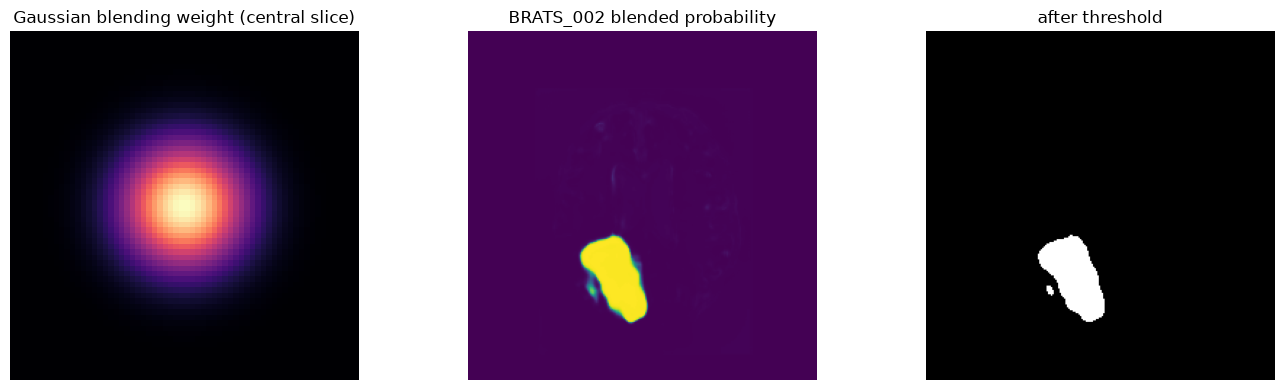

In [23]:
stride = int(round(PATCH * (1 - OVERLAP)))
w = su.gaussian_weight(PATCH)
cid0 = test_ids[0]
prob0, info0 = predict_full(final_model, cid0)
print(f"Patch {PATCH}^3, overlap {OVERLAP:.0%}, stride {stride} voxels; {info0['n_windows']} windows for {cid0} "
      f"(cropped grid {META[cid0]['cached_shape'][1:]}); last window aligned to the volume end.")
print("Blending: each window's sigmoid probabilities x Gaussian importance map (sigma = PATCH/8, centre weight 1);")
print("          sum over windows / sum of weights  ->  THEN threshold at", THRESH)
print("Prediction is pasted back into the native 240x240x155 grid using the stored crop box.")
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(w[:, :, PATCH // 2], cmap="magma"); ax[0].set_title("Gaussian blending weight (central slice)")
c0 = tuple(int(v) for v in ndimage.center_of_mass(prob0 >= THRESH)) if (prob0 >= THRESH).any() else (120, 120, 77)
ax[1].imshow(prob0[:, :, c0[2]].T, cmap="viridis", origin="lower", vmin=0, vmax=1); ax[1].set_title(f"{cid0} blended probability")
ax[2].imshow((prob0[:, :, c0[2]] >= THRESH).T, cmap="gray", origin="lower"); ax[2].set_title("after threshold")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### F2 [4] — Test-set metrics (first and only use of test labels)

In [24]:
test_vol = pd.Series({cid: tumor_ml_from_label(split_df.set_index('case_id').loc[cid].label_relpath) for cid in test_ids})
print("B3 completed now that test labels may be used - test reference volume (mL):")
display(test_vol.describe().to_frame("test tumor mL").T)

with su.Timer() as t_test:
    test_raw, test_masks_raw = evaluate(final_model, test_ids, keep_masks=True)
print(f"Inference + metrics on {len(test_ids)} test volumes: {t_test.dt/60:.1f} min")

def metric_summary(df):
    cols = ["dice", "iou", "sensitivity", "hd95_mm"]
    s = df[cols].agg(["mean", "std", "median"]).T
    s["n_nan"] = df[cols].isna().sum()
    return s
display(metric_summary(test_raw))
print("Empty predictions:", int(test_raw.empty_pred.sum()), "of", len(test_raw), "(HD95 is undefined/NaN for those)")
test_raw.to_csv(OUT_DIR / "test_metrics_no_postproc.csv", index=False)
display(test_raw[["case_id", "dice", "iou", "sensitivity", "hd95_mm"]].round(3))

B3 completed now that test labels may be used - test reference volume (mL):


,count,mean,std,min,25%,50%,75%,max
test tumor mL,73.0,107.388,66.278,10.101,54.356,89.113,157.749,318.345


Inference + metrics on 73 test volumes: 3.8 min


,mean,std,median,n_nan
dice,0.879,0.077,0.896,0
iou,0.792,0.110,0.811,0
sensitivity,0.891,0.094,0.916,0
hd95_mm,8.594,11.189,4.472,0


Empty predictions: 0 of 73 (HD95 is undefined/NaN for those)


,case_id,dice,iou,sensitivity,hd95_mm
0,BRATS_002,0.875,0.777,0.989,3.742
1,BRATS_012,0.914,0.842,0.923,4.359
2,BRATS_016,0.895,0.809,0.967,3.742
3,BRATS_033,0.947,0.899,0.966,2.000
4,BRATS_039,0.867,0.765,0.787,3.606
...,...,...,...,...,...
68,BRATS_462,0.818,0.692,0.756,6.708
69,BRATS_466,0.896,0.812,0.979,2.236
70,BRATS_467,0.932,0.873,0.906,59.463
71,BRATS_481,0.872,0.774,0.888,31.081


### F3 [3] — Tumor volume (mL) and volume error per case

Volume (mL) = voxel count x (sx*sy*sz mm^3) / 1000; spacing read from each NIfTI header (1x1x1 mm here).


,case_id,ref_ml,pred_ml,abs_vol_err_ml,pct_vol_err
0,BRATS_002,63.06,79.53,16.47,26.12
1,BRATS_012,21.61,22.02,0.41,1.89
2,BRATS_016,82.73,96.13,13.41,16.20
3,BRATS_033,114.02,118.59,4.58,4.02
4,BRATS_039,37.01,30.19,6.83,-18.44
...,...,...,...,...,...
68,BRATS_462,38.31,32.53,5.78,-15.09
69,BRATS_466,16.75,19.86,3.11,18.60
70,BRATS_467,157.75,148.73,9.02,-5.72
71,BRATS_481,57.17,59.23,2.06,3.60


,abs_vol_err_ml,pct_vol_err
mean,12.77,3.16
std,13.19,19.82
median,8.44,1.48


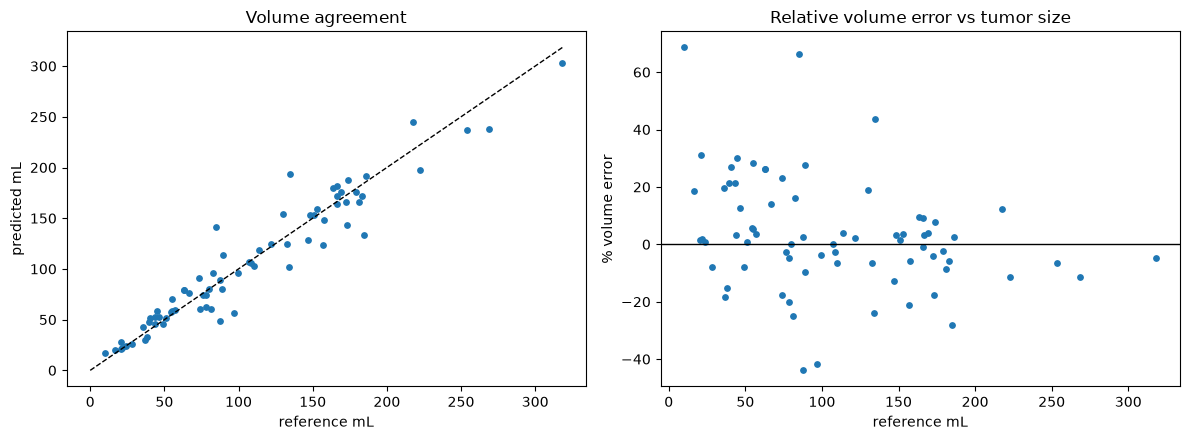

In [25]:
vol_tab = test_raw[["case_id", "ref_ml", "pred_ml", "abs_vol_err_ml", "pct_vol_err"]].copy()
print("Volume (mL) = voxel count x (sx*sy*sz mm^3) / 1000; spacing read from each NIfTI header (1x1x1 mm here).")
display(vol_tab.round(2))
display(vol_tab[["abs_vol_err_ml", "pct_vol_err"]].agg(["mean", "std", "median"]).round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(vol_tab.ref_ml, vol_tab.pred_ml, s=15); mx = vol_tab[["ref_ml", "pred_ml"]].max().max()
ax[0].plot([0, mx], [0, mx], "k--", lw=1); ax[0].set_xlabel("reference mL"); ax[0].set_ylabel("predicted mL"); ax[0].set_title("Volume agreement")
ax[1].scatter(vol_tab.ref_ml, vol_tab.pct_vol_err, s=15); ax[1].axhline(0, c="k", lw=1)
ax[1].set_xlabel("reference mL"); ax[1].set_ylabel("% volume error"); ax[1].set_title("Relative volume error vs tumor size")
plt.tight_layout(); plt.savefig(OUT_DIR / "F3_volume.png", dpi=110); plt.show()

### F4 [4] — Connected-component postprocessing

**Rule (fixed before looking at test results):** remove 26-connected predicted components smaller than **0.5 mL**.
*Rationale:* whole tumor (edema + core) is a large region, typically tens of mL. Isolated specks of a few voxels are usually false positives (vessels, FLAIR artefacts, patch-border noise). A *size* threshold, unlike "keep only the largest component", keeps genuinely multifocal lesions.
*Decision protocol:* the rule is kept only if it does not reduce mean **validation** Dice. Test results are reported before and after for transparency, but are not used to decide.

In [26]:
sp_val = {cid: np.array(META[cid]["spacing"]) for cid in val_ids}
val_pp = pd.DataFrame([dict(case_id=cid, **su.seg_metrics(su.remove_small_components(val_masks[FINAL][cid], sp_val[cid], MIN_CC_ML),
                                                         load_ref(cid), sp_val[cid])) for cid in val_ids])
dec = pd.DataFrame({"validation before": summarise(val_res[FINAL]), "validation after": summarise(val_pp)}).T
display(dec[["Dice mean", "Dice median", "HD95 mm mean", "HD95 mm median", "FP volume mL mean", "Sensitivity mean"]])
KEEP_PP = val_pp.dice.mean() >= val_res[FINAL].dice.mean()
print("Decision from VALIDATION:", "KEEP the rule" if KEEP_PP else "DROP the rule")

test_pp = pd.DataFrame([dict(case_id=cid, **su.seg_metrics(su.remove_small_components(test_masks_raw[cid], np.array(META[cid]['spacing']), MIN_CC_ML),
                                                          load_ref(cid), np.array(META[cid]['spacing']))) for cid in test_ids])
cmp = pd.DataFrame({"test before": summarise(test_raw), "test after": summarise(test_pp)}).T
display(cmp[["Dice mean", "Dice sd", "Dice median", "HD95 mm mean", "HD95 mm median", "FP volume mL mean", "Sensitivity mean", "empty predictions"]])
test_pp.to_csv(OUT_DIR / "test_metrics_postproc.csv", index=False)

TEST_FINAL = test_pp if KEEP_PP else test_raw
test_masks_final = ({cid: su.remove_small_components(test_masks_raw[cid], np.array(META[cid]['spacing']), MIN_CC_ML) for cid in test_ids}
                    if KEEP_PP else test_masks_raw)
print("Final test results (rule", "applied)" if KEEP_PP else "not applied)")
display(metric_summary(TEST_FINAL))

,Dice mean,Dice median,HD95 mm mean,HD95 mm median,FP volume mL mean,Sensitivity mean
validation before,0.856,0.884,19.395,5.385,14.590,0.89
validation after,0.859,0.885,17.697,4.583,14.218,0.89


Decision from VALIDATION: KEEP the rule


,Dice mean,Dice sd,Dice median,HD95 mm mean,HD95 mm median,FP volume mL mean,Sensitivity mean,empty predictions
test before,0.879,0.077,0.896,8.594,4.472,11.234,0.891,0.0
test after,0.881,0.077,0.896,8.208,4.243,10.958,0.890,0.0


Final test results (rule applied)


,mean,std,median,n_nan
dice,0.881,0.077,0.896,0
iou,0.794,0.110,0.812,0
sensitivity,0.890,0.095,0.916,0
hd95_mm,8.208,10.804,4.243,0


**F4 interpretation.** The rule was fixed in advance (remove 26-connected components < 0.5 mL) and **kept because of the validation result**: Dice 0.856 → 0.859, mean HD95 19.4 → 17.7 mm (median 5.4 → 4.6 mm), FP volume 14.6 → 14.2 mL, sensitivity unchanged (0.890). On test it behaves the same way (Dice 0.879 → 0.881, mean HD95 8.6 → 8.2 mm, median 4.47 → 4.24 mm). The test numbers are shown for transparency only; the decision would have been the same if they had gone the other way.

The rule mainly improves **HD95, not Dice**. A few voxels of isolated false positive far from the tumor barely change overlap, but they dominate the 95th-percentile surface distance. The risk is deleting a genuine small satellite lesion under 0.5 mL: sensitivity drops very slightly (0.891 → 0.890). A size threshold was chosen over "keep the largest component" precisely to preserve multifocal disease.

---
## G. Three-plane error analysis and limitations (10 marks)

### G1 [3] — Best, median and worst test cases: three planes with reference and prediction

{'worst': 'BRATS_078', 'median': 'BRATS_156', 'best': 'BRATS_112'}


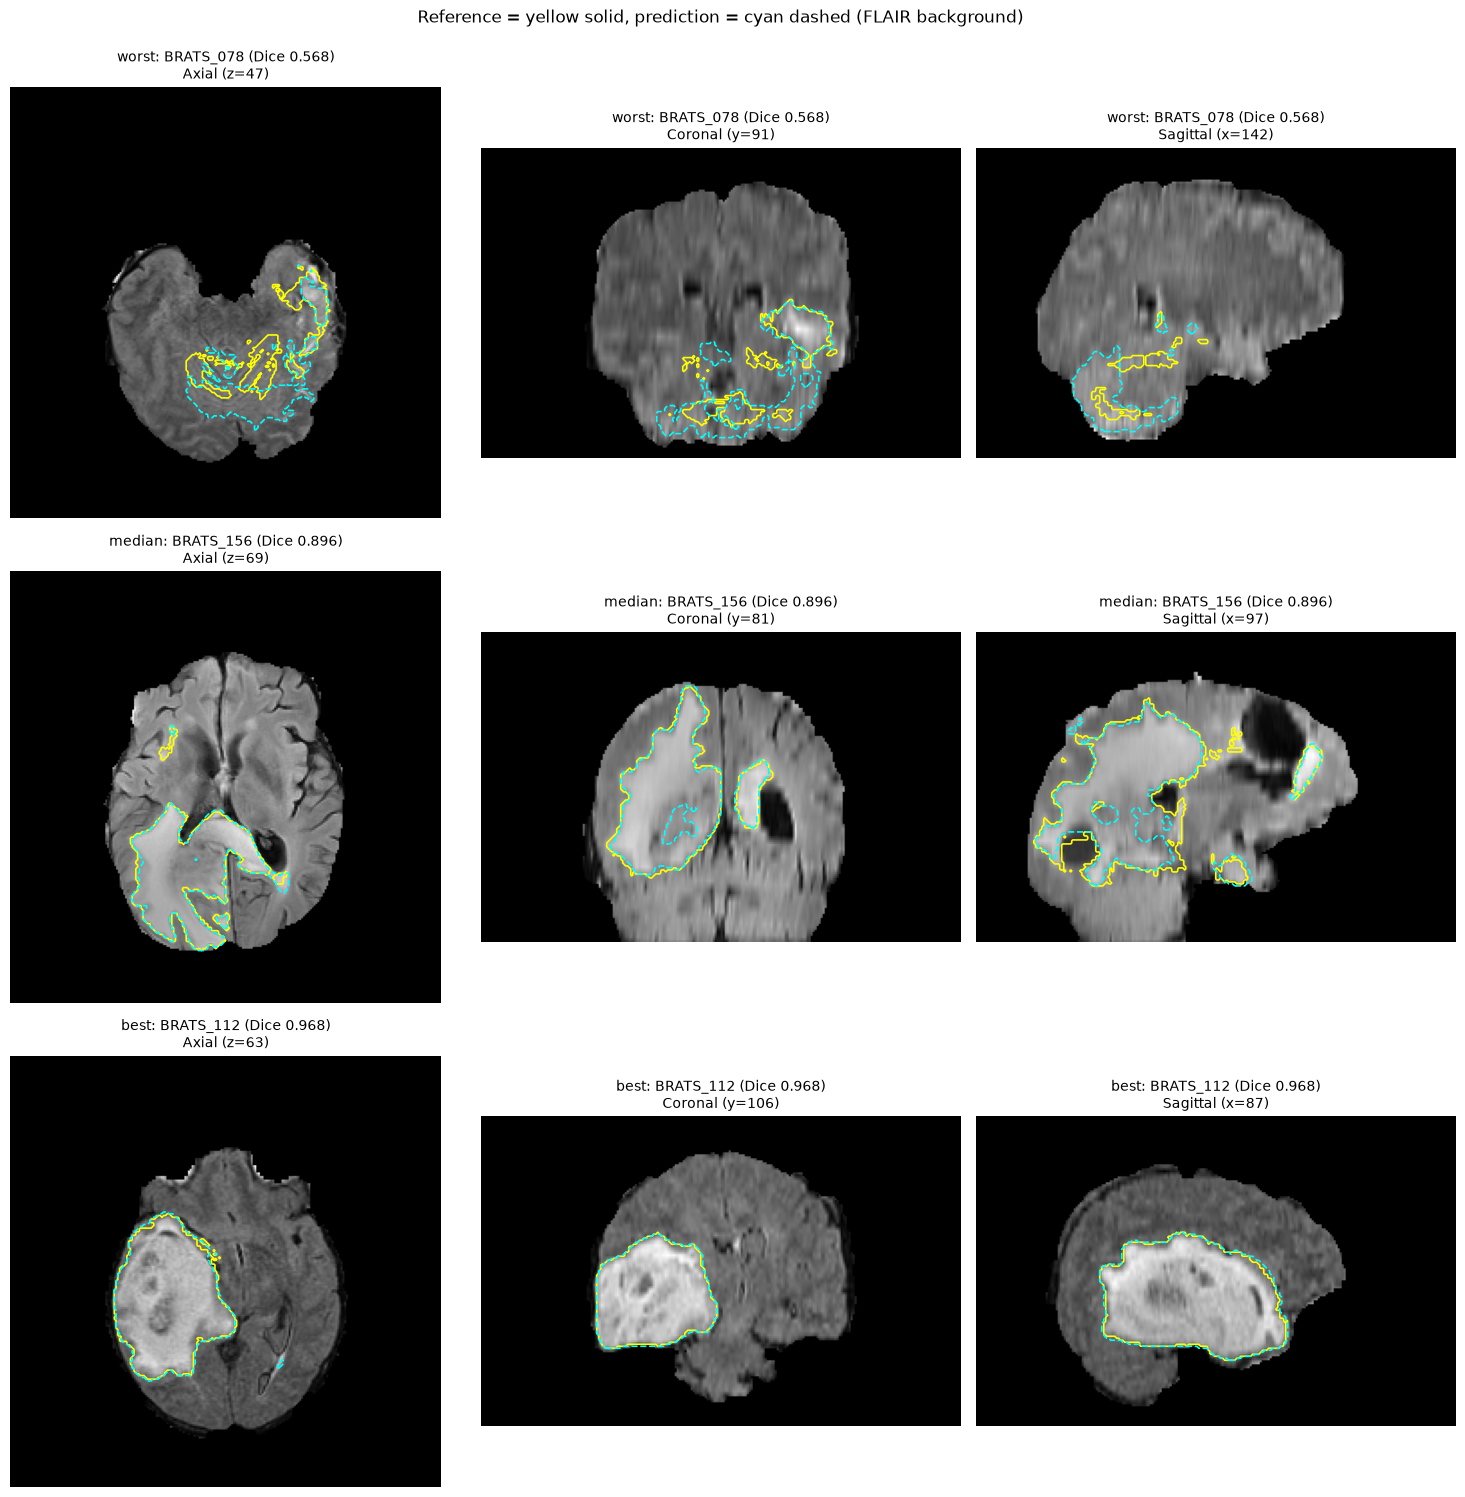

In [27]:
ranked = TEST_FINAL.sort_values("dice").reset_index(drop=True)
picks = {"worst": ranked.iloc[0].case_id, "median": ranked.iloc[len(ranked) // 2].case_id, "best": ranked.iloc[-1].case_id}
print(picks)

def case_views(cid):
    r = split_df.set_index("case_id").loc[cid]
    flair = np.asarray(nib.load(DATA_ROOT / r.image_relpath).dataobj, dtype=np.float32)[..., 0]
    ref, pred = load_ref(cid), test_masks_final[cid]
    centre = tuple(int(round(c)) for c in ndimage.center_of_mass(ref | pred))
    return flair, ref, pred, centre

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for i, (tag, cid) in enumerate(picks.items()):
    flair, ref, pred, centre = case_views(cid)
    dsc = TEST_FINAL.set_index("case_id").loc[cid, "dice"]
    for j, ((title, f2), r2, p2) in enumerate(zip(su.plane_slices(flair, centre).items(),
                                                  su.plane_slices(ref, centre).values(), su.plane_slices(pred, centre).values())):
        ax = axes[i, j]
        ax.imshow(f2, cmap="gray", origin="lower")
        if r2.any(): ax.contour(r2, [0.5], colors="yellow", linewidths=1.2)
        if p2.any(): ax.contour(p2, [0.5], colors="cyan", linewidths=1.2, linestyles="--")
        ax.set_title(f"{tag}: {cid} (Dice {dsc:.3f})\n{title}", fontsize=10); ax.axis("off")
fig.suptitle("Reference = yellow solid, prediction = cyan dashed (FLAIR background)", y=0.995)
plt.tight_layout(); plt.savefig(OUT_DIR / "G1_three_planes.png", dpi=100); plt.show()

### G2 [3] — True positive / false positive / false negative maps

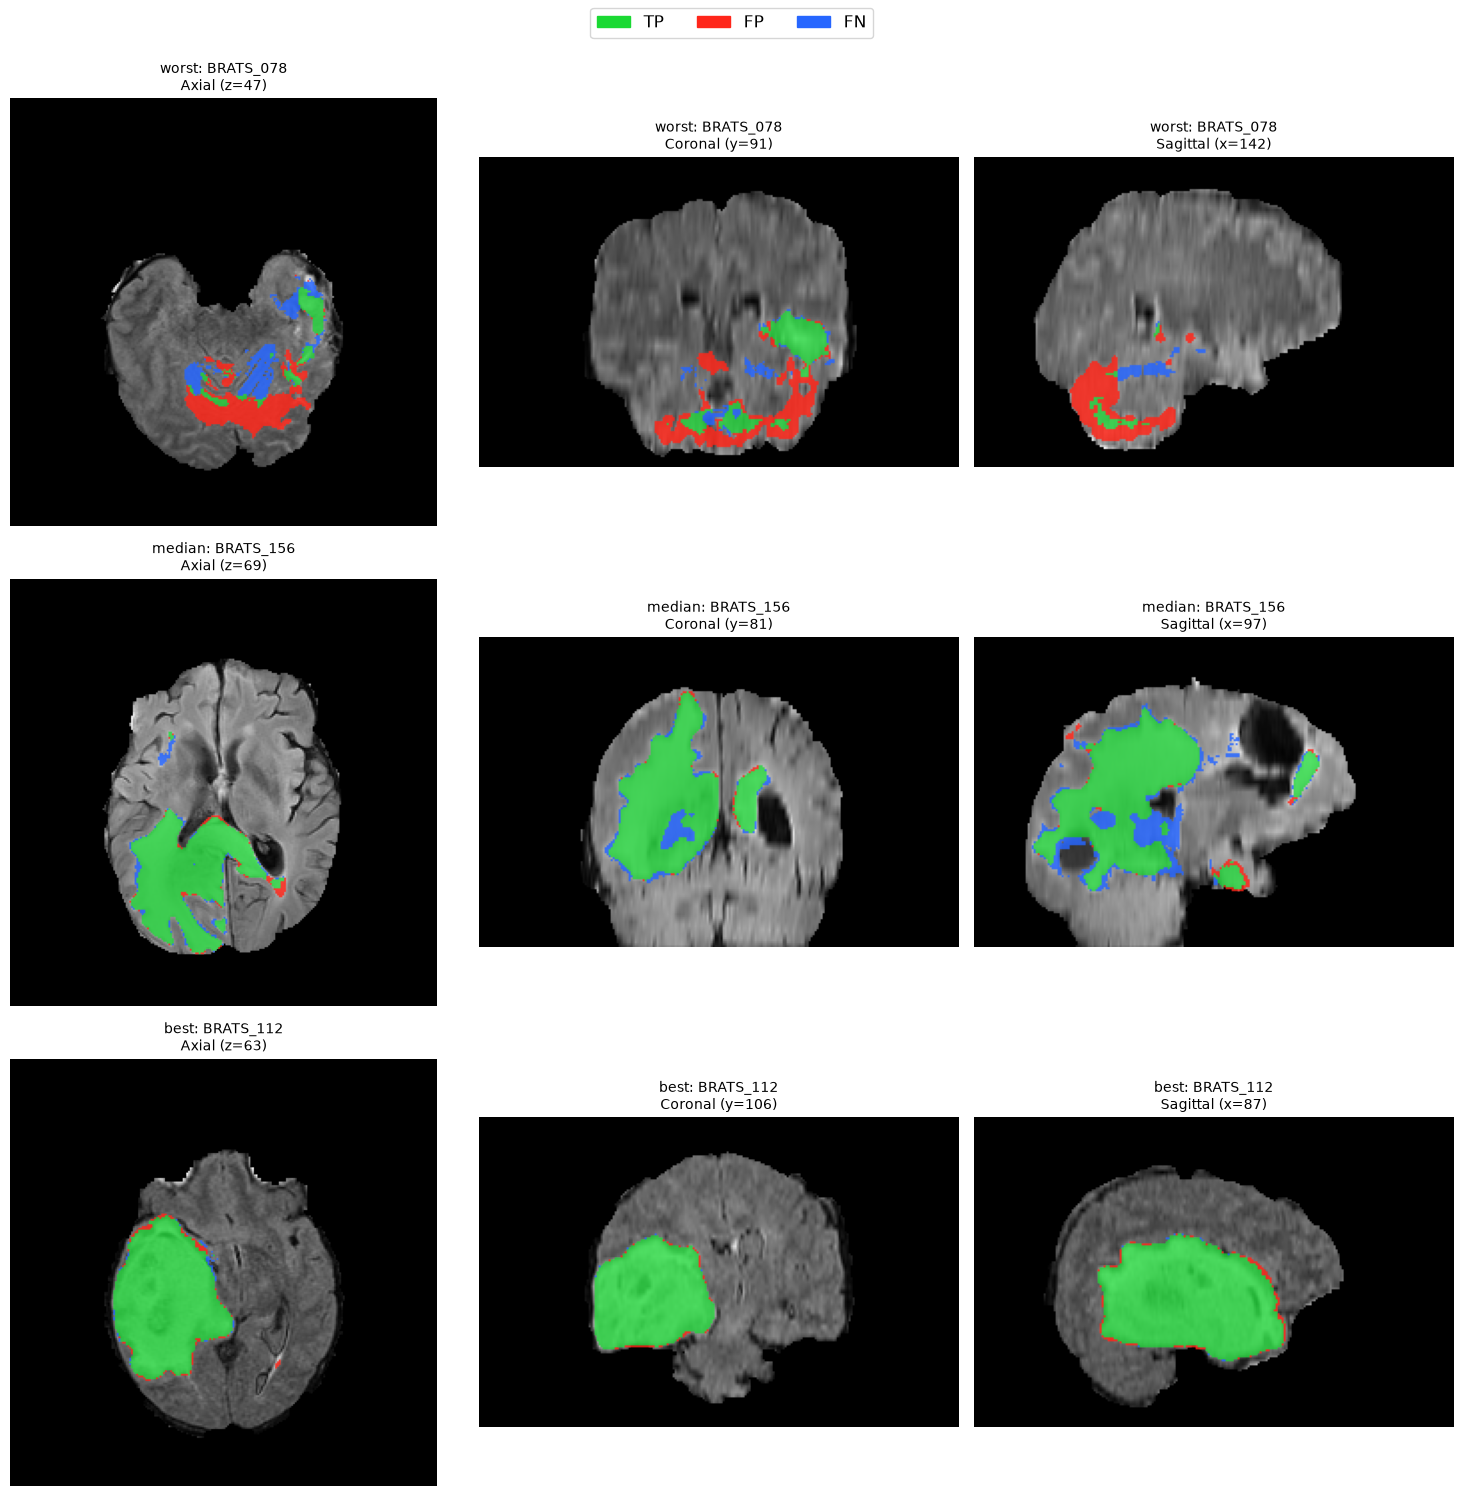

,case,case_id,ref_ml,fp_ml,fn_ml,fp_within_2mm_of_boundary,fn_within_2mm_of_boundary,fp_components,fn_components
0,worst,BRATS_078,85.083,76.578,20.984,0.279,0.648,107,114
1,median,BRATS_156,222.612,8.877,34.710,0.944,0.780,366,348
2,best,BRATS_112,169.185,8.673,2.195,0.927,0.984,233,336


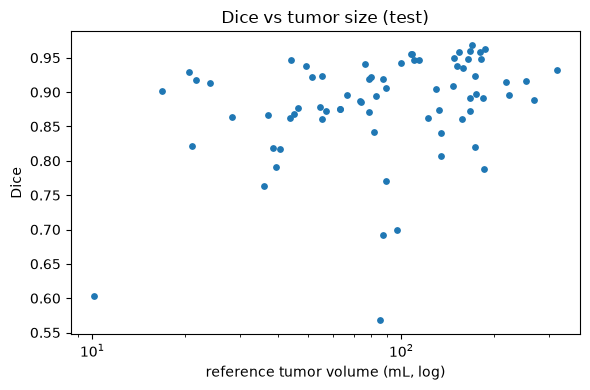

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for i, (tag, cid) in enumerate(picks.items()):
    flair, ref, pred, centre = case_views(cid)
    rgba = su.error_rgb(pred, ref)
    for j, (title, f2) in enumerate(su.plane_slices(flair, centre).items()):
        x, y, zc = centre
        e2 = [rgba[:, :, zc].transpose(1, 0, 2), rgba[:, y, :].transpose(1, 0, 2), rgba[x, :, :].transpose(1, 0, 2)][j]
        axes[i, j].imshow(f2, cmap="gray", origin="lower"); axes[i, j].imshow(e2, origin="lower")
        axes[i, j].set_title(f"{tag}: {cid}\n{title}", fontsize=10); axes[i, j].axis("off")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=(0.1, 0.85, 0.2), label="TP"), Patch(color=(1, 0.15, 0.1), label="FP"),
                    Patch(color=(0.15, 0.4, 1), label="FN")], loc="upper center", ncol=3, fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.savefig(OUT_DIR / "G2_error_maps.png", dpi=100); plt.show()


rows = []
for tag, cid in picks.items():
    ref, pred = load_ref(cid), test_masks_final[cid]
    dist_out = ndimage.distance_transform_edt(~ref); dist_in = ndimage.distance_transform_edt(ref)
    fp, fn = pred & ~ref, ref & ~pred
    rows.append(dict(case=tag, case_id=cid, ref_ml=ref.sum() / 1000, fp_ml=fp.sum() / 1000, fn_ml=fn.sum() / 1000,
                     fp_within_2mm_of_boundary=(dist_out[fp] <= 2).mean() if fp.any() else np.nan,
                     fn_within_2mm_of_boundary=(dist_in[fn] <= 2).mean() if fn.any() else np.nan,
                     fp_components=ndimage.label(fp, np.ones((3, 3, 3)))[1], fn_components=ndimage.label(fn, np.ones((3, 3, 3)))[1]))
G2 = pd.DataFrame(rows); display(G2.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(TEST_FINAL.ref_ml, TEST_FINAL.dice, s=15)
ax.set_xscale("log"); ax.set_xlabel("reference tumor volume (mL, log)"); ax.set_ylabel("Dice"); ax.set_title("Dice vs tumor size (test)")
plt.tight_layout(); plt.savefig(OUT_DIR / "G2_dice_vs_size.png", dpi=110); plt.show()

**G2 interpretation.**
- **Best, BRATS_112 (Dice 0.968):** a large, compact, well-contrasted lesion. 93% of FP and 98% of FN voxels lie within 2 mm of the reference boundary, so the only errors are a one-voxel rim, i.e. ordinary **boundary disagreement**. That is the same order as inter-rater variability.
- **Median, BRATS_156 (Dice 0.896):** errors are again boundary errors (94% of FP within 2 mm), but there is a systematic **under-segmentation** (FN 34.7 mL vs FP 8.9 mL). The blue regions sit inside the lesion around dark, low-FLAIR cavity and necrotic tissue next to the ventricle. Locally these do not look like bright edema, yet the annotators included them in whole tumor. Telling them apart needs context about the surrounding enhancing rim.
- **Worst, BRATS_078 (Dice 0.568):** a different failure type. Only 28% of the 76.6 mL of false positives lie near the reference boundary, spread over 107 separate components in the **posterior fossa and cerebellum** (axial z = 47). FLAIR intensity at the skull base is often inhomogeneous and bright. A 64 mm patch centred there contains no tumor and no contralateral reference tissue, so the network cannot tell this normal brightness from edema; this is a **patch-context** error. Infratentorial tumors are also rare in the training data. Part of the real lesion is missed as well (FN 21 mL).
- **Small structures:** Dice correlates with tumor size (Spearman ρ = 0.33, p = 0.004, scatter plot above). The smallest test tumor, BRATS_376 (10.1 mL), has Dice 0.60 and HD95 33.6 mm: with a small denominator, every misplaced voxel or distant speck costs proportionally more.

### G3 [2] — Dice vs HD95 vs volume error for these cases

In [29]:
G3 = TEST_FINAL.set_index("case_id").loc[list(picks.values()), ["dice", "iou", "sensitivity", "hd95_mm", "ref_ml", "pred_ml", "abs_vol_err_ml", "pct_vol_err"]]
G3.insert(0, "case", list(picks.keys())); display(G3.round(3))
print("Spearman correlations over all test cases:")
display(TEST_FINAL[["dice", "hd95_mm", "abs_vol_err_ml"]].corr(method="spearman").round(2))

,case,dice,iou,sensitivity,hd95_mm,ref_ml,pred_ml,abs_vol_err_ml,pct_vol_err
case_id,,,,,,,,,
BRATS_078,worst,0.568,0.397,0.753,10.488,85.083,140.677,55.594,65.341
BRATS_156,median,0.896,0.812,0.844,3.606,222.612,196.779,25.833,-11.604
BRATS_112,best,0.968,0.939,0.987,1.414,169.185,175.663,6.478,3.829


Spearman correlations over all test cases:


,dice,hd95_mm,abs_vol_err_ml
dice,1.00,-0.74,-0.52
hd95_mm,-0.74,1.00,0.45
abs_vol_err_ml,-0.52,0.45,1.00


**G3 — Why one metric cannot summarise every failure.**

| case | Dice | HD95 (mm) | volume error |
|---|---|---|---|
| worst BRATS_078 | 0.568 | 10.5 | +55.6 mL (+65%) |
| median BRATS_156 | 0.896 | 3.6 | −25.8 mL (−12%) |
| best BRATS_112 | 0.968 | 1.4 | +6.5 mL (+4%) |

The three metrics agree on the ordering of these three cases, but over all test cases they are only partly related (Spearman: Dice–HD95 −0.74, Dice–|volume error| −0.52, HD95–|volume error| 0.45), and each misses failures the others catch:
- **Dice** measures overlap. It is insensitive to a tiny false-positive island far away (BRATS_467: Dice 0.93 but HD95 59 mm) and is structurally lower for small tumors.
- **HD95** measures the worst boundary or outlier distance. It explodes from one distant speck even when the segmentation is excellent, and says nothing about how much tissue is wrong.
- **Volume error** can be near zero while the segmentation is wrong, because FP and FN cancel. The median case misses 34.7 mL and adds 8.9 mL, so net volume error understates its total misclassification (43.6 mL). Volume error is also the clinically relevant number for growth monitoring.

A failure can be "good" on one metric and "bad" on another, so overlap, boundary distance and volume must be reported together. This is the same reasoning as Metrics Reloaded (Maier-Hein et al., 2024).

### G4 [2] — Limitations

**G4 — Limitations.**
1. **Small training budget:** 2,000 steps (8,000 patches of 64³, ~35 min on an Apple M4 Max), a single run and a single seed. Validation Dice was still rising, so the reported scores underestimate what this architecture can reach. The uniform vs tumor-aware difference (+0.003 Dice) is within run-to-run noise.
2. **No external-site validation:** train, validation and test all come from the same MSD/BraTS 2016–17 collection, which is already skull-stripped, co-registered and resampled to 1 mm with harmonised protocols. Performance on raw clinical scans from other scanners, field strengths or institutions (and on non-glioma pathology) is unknown and probably lower.
3. **Reference standard:** labels are human research annotations with known inter-rater variability at the edema boundary, not pathology-confirmed tumor extent. A Dice around 0.9 is close to that agreement ceiling.
4. **Limited context and target:** 64 mm patches cannot see the whole brain (cf. the posterior-fossa false positives in BRATS_078), and only the binary whole tumor was modelled. Tumor core and enhancing tumor, which matter most clinically, were not.
5. **Minor protocol bias:** checkpoint selection used 8 validation cases that are also part of the 73-case validation comparison. MPS GPU kernels are not bit-wise deterministic.

---
## Bonus 1 — Missing-modality stress test

zero FLAIR: 4.0 min


zero T1: 4.1 min


zero T1ce: 3.9 min


zero T2: 4.0 min


,Dice mean,Dice median,HD95 mm median,HD95 mm mean,|vol err| mL mean,vol err % median,empty preds,ΔDice vs 4ch
all 4 channels,0.881,0.896,4.243,8.208,12.662,1.114,0.0,0.000
zero FLAIR,0.366,0.398,25.397,29.859,72.141,-71.046,6.0,-0.515
zero T1,0.801,0.826,25.200,32.846,31.994,30.695,0.0,-0.079
zero T1ce,0.849,0.873,5.916,9.869,18.725,-1.386,0.0,-0.032
zero T2,0.847,0.877,5.385,10.097,19.352,-3.842,0.0,-0.033


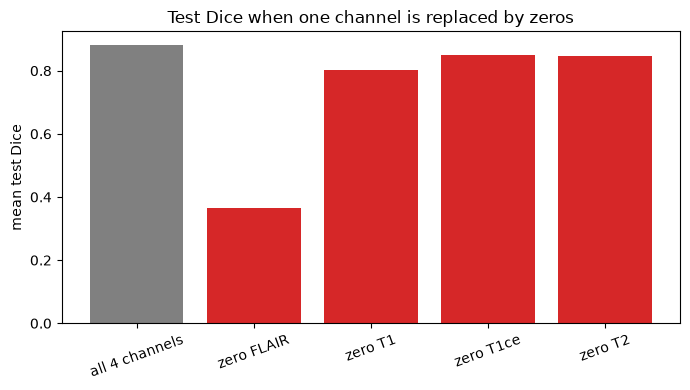

In [30]:
if RUN_BONUS:
    def eval_cond(**kw):
        df, _ = evaluate(final_model, test_ids, postprocess=KEEP_PP, **kw)
        return df
    bonus1 = {"all 4 channels": TEST_FINAL}
    for c, n in enumerate(su.CHANNELS):
        with su.Timer() as t:
            bonus1[f"zero {n}"] = eval_cond(zero_channel=c)
        print(f"zero {n}: {t.dt/60:.1f} min")
    B1 = pd.DataFrame({k: {"Dice mean": v.dice.mean(), "Dice median": v.dice.median(), "HD95 mm median": v.hd95_mm.median(),
                           "HD95 mm mean": v.hd95_mm.mean(), "|vol err| mL mean": v.abs_vol_err_ml.mean(),
                           "vol err % median": v.pct_vol_err.median(), "empty preds": int(v.empty_pred.sum())}
                       for k, v in bonus1.items()}).T
    B1["ΔDice vs 4ch"] = B1["Dice mean"] - B1.loc["all 4 channels", "Dice mean"]
    display(B1.round(3))
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(B1.index, B1["Dice mean"], color=["grey"] + ["tab:red"] * 4); ax.set_ylabel("mean test Dice")
    ax.set_title("Test Dice when one channel is replaced by zeros"); plt.xticks(rotation=20)
    plt.tight_layout(); plt.savefig(OUT_DIR / "bonus1_missing_modality.png", dpi=110); plt.show()

**Bonus 1 interpretation.** **FLAIR is by far the most influential channel.** Zeroing it collapses mean test Dice from 0.881 to 0.366, gives 6 empty predictions, raises median HD95 from 4.2 to 25.4 mm and shrinks volumes (median −71%). Whole tumor is defined largely by peritumoral edema, which is exactly what FLAIR shows best. Zeroing T1 is the second most harmful (Dice 0.801) and fails in a different way: volumes are *over*-estimated (+31%) and median HD95 jumps to 25 mm, so the model starts calling distant tissue tumor. Removing T1ce or T2 costs only about 0.03 Dice, because T2 and FLAIR carry largely redundant edema information and T1ce mainly informs the enhancing core.

Zeroing is an imperfect simulation of a missing scan. After z-scoring, 0 means "average brain intensity", so the zeroed channel becomes a perfectly flat, average-tissue image that the network never saw in training. That is an out-of-distribution input, not an "unknown" signal, and the network has no way to know the channel is absent. A genuinely missing acquisition might instead be replaced by a different protocol, a lower-quality scan or a synthesised image, each with its own artefacts.

To handle missing modalities, training could use **modality dropout** (randomly blank channels and add binary "available" indicator channels), per-modality encoders fused by order-independent statistics (HeMIS-style), or knowledge distillation from a full-modality teacher. Any of these would need validation with genuinely incomplete cases.

---
## Bonus 2 — Sliding-window seam test

,overlap,stride,windows (median case),runtime incl. metrics (min),Dice mean,Dice median,HD95 mm median,|vol err| mL mean
0,0%,64,27,1.632,0.859,0.883,5.000,14.755
1,25%,48,36,2.014,0.873,0.891,5.099,13.277
2,50%,32,80,3.768,0.881,0.896,4.243,12.662


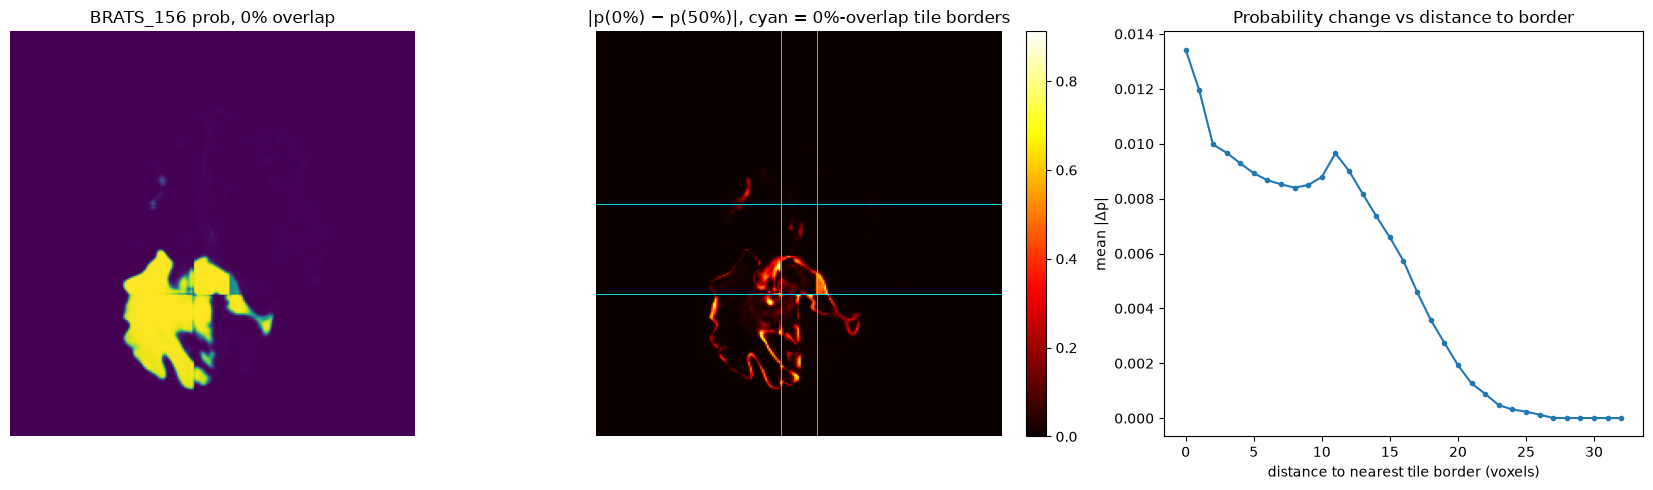

In [31]:
if RUN_BONUS:
    rows, probs = [], {}
    seam_case = picks["median"]
    for ov in [0.0, 0.25, 0.5]:
        if DEVICE == "mps": torch.mps.synchronize()
        with su.Timer() as t:
            df, _ = evaluate(final_model, test_ids, postprocess=KEEP_PP, overlap=ov)
        probs[ov], info = predict_full(final_model, seam_case, overlap=ov)
        rows.append({"overlap": f"{ov:.0%}", "stride": info["stride"], "windows (median case)": info["n_windows"],
                     "runtime incl. metrics (min)": t.dt / 60, "Dice mean": df.dice.mean(), "Dice median": df.dice.median(),
                     "HD95 mm median": df.hd95_mm.median(), "|vol err| mL mean": df.abs_vol_err_ml.mean()})
    B2 = pd.DataFrame(rows); display(B2.round(4))

    # probability difference near patch borders (0% overlap tiles the volume -> borders are known exactly)
    diff = np.abs(probs[0.0] - probs[0.5])
    (x0, x1), (y0, y1), (z0, z1) = META[seam_case]["box"]
    shp = META[seam_case]["cached_shape"][1:]
    def border_dist(n):                       # distance of each index to the nearest 0%-overlap tile edge
        st = su.window_starts(n, PATCH, PATCH)
        edges = np.array(sorted(set(st + [s + PATCH for s in st])))
        return np.min(np.abs(np.arange(n)[:, None] - edges[None, :]), axis=1)
    dx, dy, dz = border_dist(shp[0]), border_dist(shp[1]), border_dist(shp[2])
    dmin = np.minimum(np.minimum(dx[:, None, None], dy[None, :, None]), dz[None, None, :])
    dsub = diff[x0:x0 + shp[0], y0:y0 + shp[1], z0:z0 + shp[2]][:x1 - x0, :y1 - y0, :z1 - z0]
    dmin = dmin[:x1 - x0, :y1 - y0, :z1 - z0]
    prof = pd.Series(dsub.ravel()).groupby(np.minimum(dmin.ravel(), PATCH // 2)).mean()

    c = tuple(int(v) for v in ndimage.center_of_mass(load_ref(seam_case)))
    fig, ax = plt.subplots(1, 3, figsize=(17, 5))
    ax[0].imshow(probs[0.0][:, :, c[2]].T, origin="lower", cmap="viridis", vmin=0, vmax=1); ax[0].set_title(f"{seam_case} prob, 0% overlap")
    im = ax[1].imshow(diff[:, :, c[2]].T, origin="lower", cmap="hot", vmin=0, vmax=max(0.05, diff[:, :, c[2]].max()))
    for s in su.window_starts(shp[0], PATCH, PATCH)[1:]: ax[1].axvline(x0 + s, c="cyan", lw=.6)
    for s in su.window_starts(shp[1], PATCH, PATCH)[1:]: ax[1].axhline(y0 + s, c="cyan", lw=.6)
    ax[1].set_title("|p(0%) − p(50%)|, cyan = 0%-overlap tile borders"); plt.colorbar(im, ax=ax[1], fraction=.046)
    ax[2].plot(prof.index, prof.values, "-o", ms=3); ax[2].set_xlabel("distance to nearest tile border (voxels)")
    ax[2].set_ylabel("mean |Δp|"); ax[2].set_title("Probability change vs distance to border")
    for a in ax[:2]: a.axis("off")
    plt.tight_layout(); plt.savefig(OUT_DIR / "bonus2_seams.png", dpi=110); plt.show()

**Bonus 2 interpretation.** More overlap steadily improves results: mean Dice 0.859 (0%) → 0.873 (25%) → 0.881 (50%), |volume error| 14.8 → 13.3 → 12.7 mL, and median HD95 5.0 / 5.1 / 4.2 mm. The cost is runtime: 27 → 36 → 80 windows for the median case, and 1.6 → 2.0 → 3.8 min for the full test set including metrics (about 2.3× from 0% to 50%).

The seam figure shows why. At 0% overlap the probability map has visible straight discontinuities along tile borders, and the mean |p(0%) − p(50%)| is largest exactly at the borders (0.013) and decays with distance into a tile. Voxels near a window edge are predicted with truncated context (zero padding inside the network, missing neighbourhood). With overlap, every voxel is also predicted from a window where it is central, and Gaussian weighting down-weights the unreliable edges before averaging. Overlap helps most when tumors cross tile borders and when the patch is small relative to the structure. Here, with 64 mm patches and ~100 mL tumors, that is almost always.

**Bias warning:** choosing the overlap (or threshold, or postprocessing) after repeatedly looking at test labels turns the test set into a tuning set. The best-looking setting partly fits test-specific noise, and the reported score becomes optimistically biased; it is no longer an independent estimate. Here 50% overlap was fixed before testing, and this comparison is reported only as a post-hoc analysis. A choice should be made on validation data.

---
## Run summary

In [32]:
total_min = (time.time() - NOTEBOOK_T0) / 60
run_info = dict(seed=SEED, device=DEVICE, cpu=cpu, torch=torch.__version__, python=sys.version.split()[0],
                patch=PATCH, batch=BATCH, iters=ITERS, lr=LR, p_fg=P_FG, overlap=OVERLAP, final_sampler=FINAL,
                postprocessing_kept=bool(KEEP_PP), train_minutes={"uniform": hist_uniform["train_minutes"], "tumor": hist_tumor["train_minutes"]},
                total_notebook_minutes=total_min)
(OUT_DIR / "run_info.json").write_text(json.dumps(run_info, indent=1))
print(json.dumps(run_info, indent=1))

{
 "seed": 42,
 "device": "mps",
 "cpu": "Apple M4 Max",
 "torch": "2.13.0",
 "python": "3.11.16",
 "patch": 64,
 "batch": 4,
 "iters": 2000,
 "lr": 0.001,
 "p_fg": 0.5,
 "overlap": 0.5,
 "final_sampler": "tumor",
 "postprocessing_kept": true,
 "train_minutes": {
  "uniform": 37.431467040266334,
  "tumor": 33.255527643749765
 },
 "total_notebook_minutes": 117.46402490139008
}
